# NLP analysis of the Piecemaker annotations: Sider

Text analysis of the annotations to *Sider* (2011) from the Piecemaker archive of The Forsythe Company. The corpus covers the rehearsal period up to the premiere on 17 June 2011. Steps: word frequencies and bigrams, selected terms over time, rank correlation, word pairs, keyness against the Brown corpus, and topic modelling with BERTopic.

In [1]:
import re
from collections import Counter
from datetime import datetime
from pathlib import Path

import nltk
import spacy
import contractions
import pandas as pd
import numpy as np
from tqdm import tqdm
from sklearn.feature_extraction.text import CountVectorizer
from scipy.stats import spearmanr
from nltk.corpus import stopwords, brown
from nltk.tokenize import sent_tokenize
from nltk.collocations import BigramCollocationFinder
from nltk.metrics import BigramAssocMeasures
from bertopic import BERTopic
from plotnine import *

In [2]:
# Download required NLTK data (only needs to run once)
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('brown')

[nltk_data] Downloading package punkt to /Users/david/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /Users/david/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /Users/david/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package brown to /Users/david/nltk_data...
[nltk_data]   Package brown is already up-to-date!


True

In [3]:
nlp = spacy.load("en_core_web_sm")
nlp.max_length = 5_000_000

## Setup

The two csv files with the archive export are read from the repository folder. They are not included here because the annotation data are not public. `LANG` sets the figure labels to English or German.


In [4]:
PIECE_ID = 108          # Sider
PIECE_TITLE = 'Sider'
filter_date = datetime(2011, 6, 17).date()    # up to the premiere

print(f'PIECE_ID={PIECE_ID}, analysing annotations before {filter_date}')

PIECE_ID=108, analysing annotations before 2011-06-17


In [5]:
LANG = 'en'   # 'de' or 'en', switches the figure labels

def L(de, en, lang=None):
    return de if (lang or LANG) == 'de' else en

PASTEL_CYCLE = ['#cd867e', '#7ec5cd', '#7ecd86', '#867ecd', '#c5cd7e', '#cd7ec5']
BAR_GREY   = '#6b6b6b'
ACCENT_RED = '#d6604d'
# line types and shapes for black-and-white print
LINETYPES = ['solid', 'dashed', 'dotted', 'dashdot']
SHAPES    = ['o', 's', '^', 'D']

theme_set(
    theme_minimal()
    + theme(plot_title=element_text(size=12),
            plot_subtitle=element_text(size=9),
            legend_title=element_blank())
)

# print size for the dissertation figures
PRINT_SIZE  = (5.8, 2.9)
PRINT_THEME = theme(text=element_text(size=8), plot_title=element_text(size=9),
                    plot_subtitle=element_text(size=7.5), axis_title=element_text(size=8),
                    axis_text=element_text(size=7.5), legend_text=element_text(size=7.5),
                    legend_title=element_blank())
FIG_DIR = Path('figures')

def de_num(x, digits=2):
    # decimal comma for German labels
    return f'{x:.{digits}f}'.replace('.', ',')

In [6]:
pieces_df = pd.read_csv("pm1-tfc-2016-pieces.csv")
events_df = pd.read_csv("pm1-tfc-2016-events.csv")
piece_map = pieces_df.set_index("id")["title"].to_dict()

In [7]:
text_df = events_df[events_df['piece_id'] == PIECE_ID].copy()

# drop entries that are only a file name (video entries)
filename_pattern = re.compile(r'^(\d{6,}|\d{4}-\d{2}-\d{2}).*\.\w{2,4}$', re.IGNORECASE)
is_filename_title = text_df['title'].apply(
    lambda t: bool(filename_pattern.match(str(t))) if pd.notna(t) else False
)
is_filename_desc = text_df['description'].apply(
    lambda d: bool(filename_pattern.match(str(d))) if pd.notna(d) else False
)
text_df = text_df[~(is_filename_title & (text_df['description'].isna() | is_filename_desc))].copy()

def combine_annotation_text(row):
    title = str(row["title"]) if pd.notna(row["title"]) else ""
    description = str(row["description"]) if pd.notna(row["description"]) else ""
    if filename_pattern.match(title.strip()):
        title = ""
    if title and not title.endswith("."):
        title += "."
    return f"{title} {description}".strip()

text_df["text"] = text_df.apply(combine_annotation_text, axis=1)
text_df["date"] = pd.to_datetime(text_df["happened_at"])
text_df["date_only"] = text_df["date"].dt.date

text_df = text_df[text_df["date_only"] < filter_date].copy()

print(f"\nAnalyzing: {piece_map.get(PIECE_ID, 'Unknown')}")
print(f"Total annotations: {len(text_df)}")
print(f"Date range: {text_df['date'].min()} to {text_df['date'].max()}")


Analyzing: Sider
Total annotations: 869
Date range: 2011-04-13 10:27:01 to 2011-06-16 18:09:16


## Preprocessing

Title and description are combined into one text per annotation, cleaned (markup, numbers, contractions) and lemmatised with spaCy. NLTK stopwords plus a hand-compiled list of company member names are excluded from all counts.


In [8]:
def clean_text(text):
    if pd.isna(text) or not text:
        return ""
    text = contractions.fix(text)
    text = re.sub(r"[\n\r\*]+", " ", text)
    text = re.sub(r"__+", " ", text)
    text = re.sub(r"\b\d+\b", "", text)
    text = re.sub(r"(?<=\w)-(?=\w)", " ", text)
    text = re.sub(r"<br\s*/?>", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[<>]", " ", text)
    text = re.sub(r"\s{2,}", " ", text).strip()
    return text

text_df["clean_text"] = text_df["text"].apply(clean_text)
text_df = text_df[text_df["clean_text"].str.len() > 0].copy()
print(f"Events after cleaning: {len(text_df)}")

Events after cleaning: 868


In [9]:
# who wrote the annotations (initials as in pm1_archive_analytics; part of the export has no author)
def first_name(s):
    return s.str.lower().str.extract(r'^([a-z]+)')[0].str.capitalize()

all_names = first_name(pd.read_csv('pm1-tfc-2016-events.csv', usecols=['created_by'])['created_by'])
initials, used = {}, set()
for name in all_names.value_counts().index:
    label, k = name[0] + '.', 2
    while label in used:
        label, k = name[:k] + '.', k + 1
    used.add(label)
    initials[name] = label

authors = first_name(text_df['created_by']).map(initials).fillna('(no author in export)')
author_shares = (authors.value_counts(normalize=True) * 100).round(1)
print(author_shares.to_string())

0
(no author in export)    43.8
F.                       43.2
B.                        8.8
D.                        4.0
Li.                       0.2


In [10]:
def lemmatize_with_spacy(text):
    doc = nlp(text)
    return " ".join(
        token.lemma_.lower()
        for token in doc
        if token.is_alpha and not token.is_stop and len(token.lemma_) >= 2
    )

text_df["lem_text"] = [
    lemmatize_with_spacy(txt)
    for txt in tqdm(text_df["clean_text"], desc="Lemmatizing")
]

Lemmatizing:   0%|          | 0/868 [00:00<?, ?it/s]

Lemmatizing:   1%|          | 6/868 [00:00<00:16, 53.01it/s]

Lemmatizing:   2%|▏         | 15/868 [00:00<00:11, 73.61it/s]

Lemmatizing:   3%|▎         | 27/868 [00:00<00:08, 94.08it/s]

Lemmatizing:   4%|▍         | 38/868 [00:00<00:08, 97.57it/s]

...

Lemmatizing:  90%|████████▉ | 781/868 [00:06<00:00, 212.23it/s]

Lemmatizing:  93%|█████████▎| 811/868 [00:06<00:00, 235.94it/s]

Lemmatizing:  97%|█████████▋| 839/868 [00:06<00:00, 248.24it/s]

Lemmatizing: 100%|█████████▉| 867/868 [00:06<00:00, 256.69it/s]

Lemmatizing: 100%|██████████| 868/868 [00:06<00:00, 128.51it/s]

In [11]:
# Manual stopword list - performer names (NER candidates, selected by hand)
confirmed_names = [
    'amancio', 'ander', 'bill', 'billy', 'brigel', 'cy', 'cyril', 'dana',
    'dana/manci', 'dave', "dave's", 'david', "david's", 'esth', 'esther',
    'fab', 'fabrice', 'feya', 'freya', 'i."', 'jasu', 'john', 'jon', 'jone',
    'jones', 'josh', 'k.', 'kati', 'katy', 'katya', 'light=', 'liz', 'm2',
    'manci', 'mancie', 'mcdonald"', 'me!', 'monica', 'music=', 'nic',
    'nicole', 'pari', 'riley', 'rob', 'roberta', 'simon', 'steven',
    'stevens', 'tanja', 'til', 'tilman', 'w.', 'w.’s', 'w=', 'ya', 'yas',
    'yasu', 'yeah!"freya', 'yoko'
]
stop_en = set(stopwords.words("english"))
custom_stopwords = list(stop_en.union(confirmed_names))
print(f"Total stopwords: {len(custom_stopwords)}")

Total stopwords: 257


In [12]:
vectorizer = CountVectorizer(stop_words=custom_stopwords)
X = vectorizer.fit_transform(text_df["lem_text"])
words = vectorizer.get_feature_names_out()
counts = X.sum(axis=0).A1
word_freq = dict(zip(words, counts))

## Word frequency

The most frequent lemmas of the corpus. Not very telling on its own, but the baseline for everything below.


In [13]:
top_words_clean = Counter(word_freq).most_common(20)
print("\nTop 20 most frequent words:")
for word, count in top_words_clean:
    print(f"  {word}: {count}")


Top 20 most frequent words:
  board: 477
  map: 220
  try: 128
  scene: 123
  like: 121
  music: 118
  hamlet: 104
  thing: 97
  text: 93
  walk: 90
  cue: 82
  go: 82
  group: 78
  people: 78
  continue: 73
  version: 70
  look: 66
  rule: 64
  foot: 61
  solo: 61


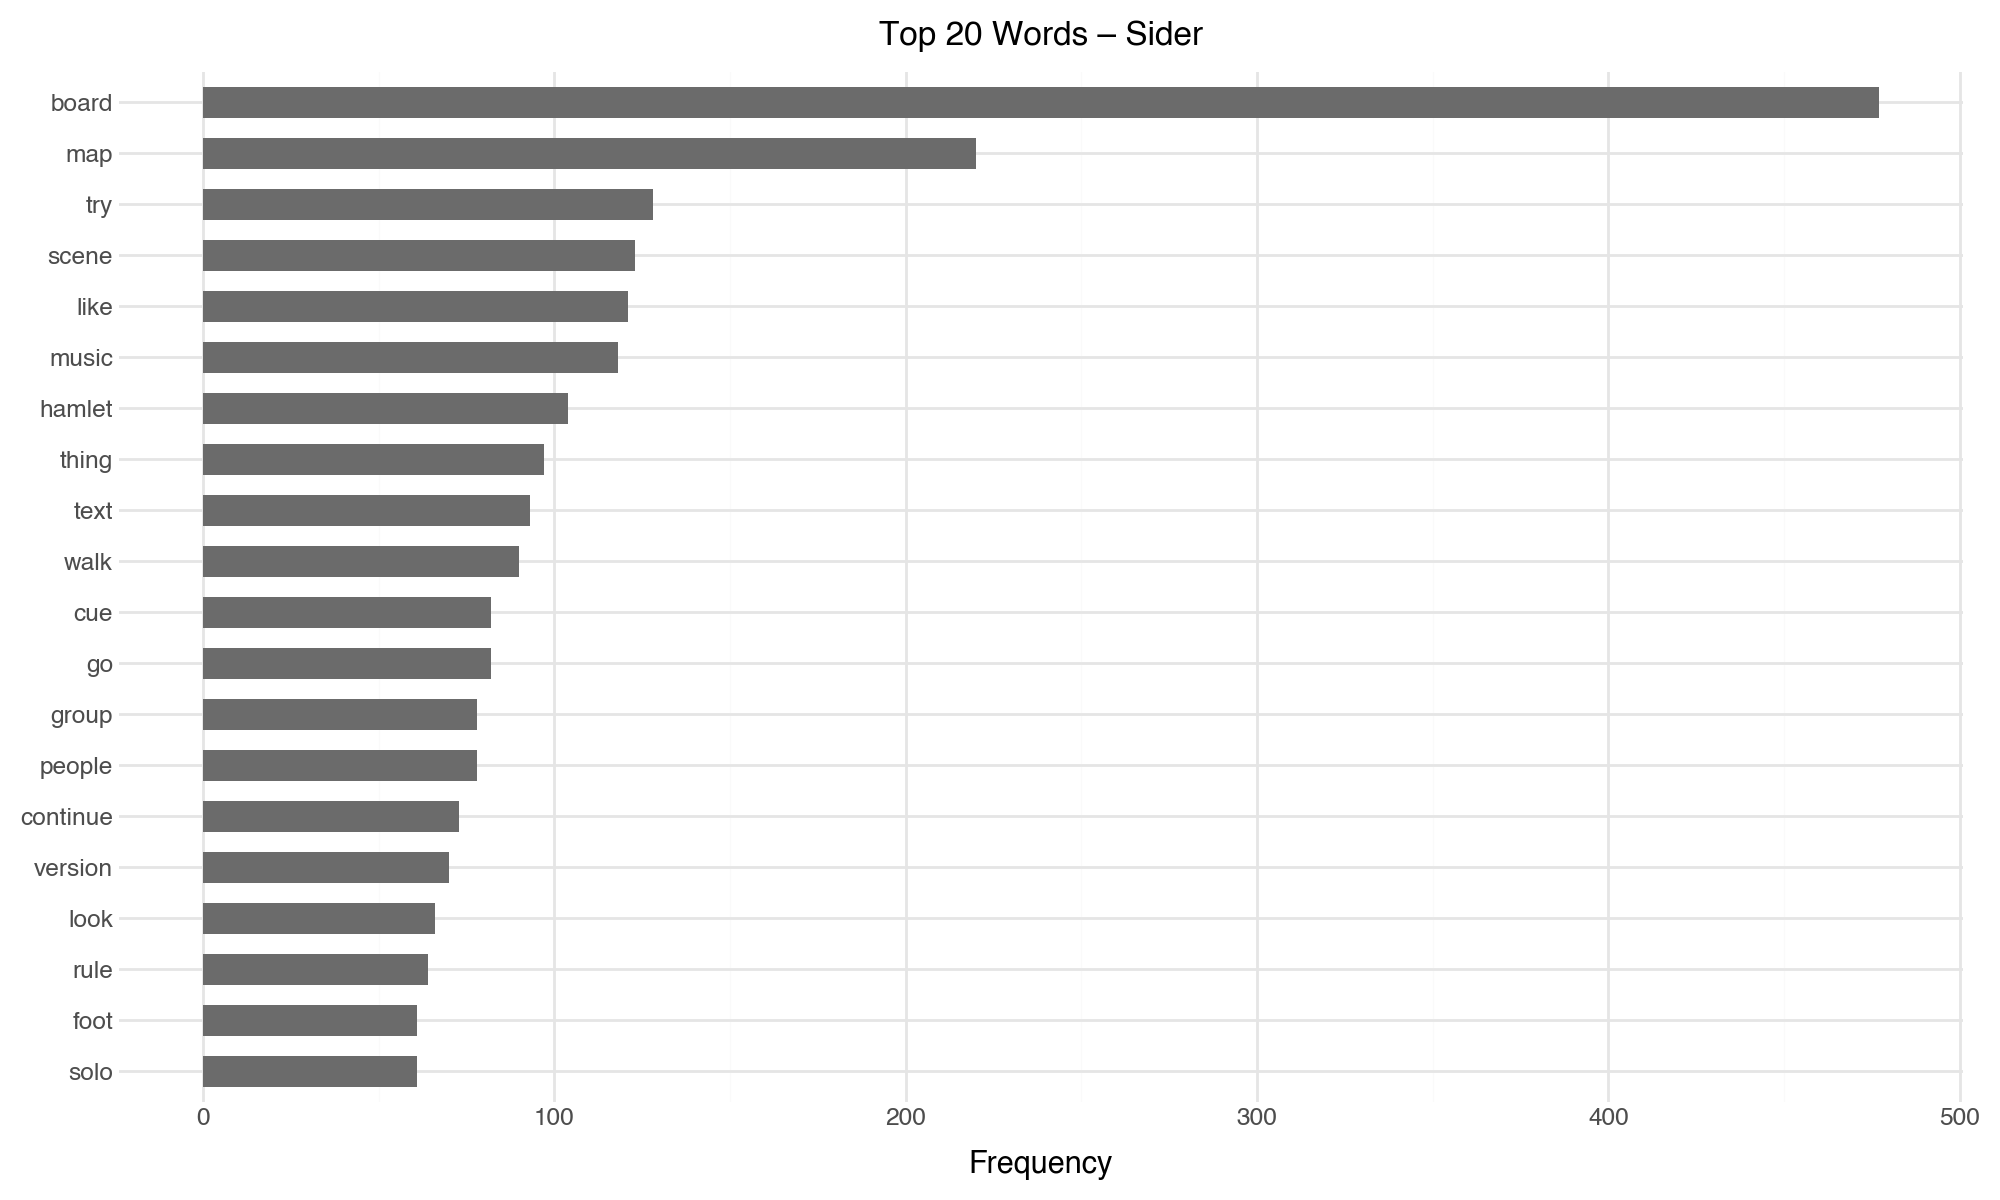

In [14]:
top_words_df = pd.DataFrame(top_words_clean, columns=['word', 'count'])
top_words_df['word'] = pd.Categorical(top_words_df['word'], categories=top_words_df['word'][::-1], ordered=True)

(ggplot(top_words_df, aes(x='word', y='count'))
 + geom_col(fill=BAR_GREY, width=0.6)
 + coord_flip()
 + labs(title=L('Häufigste Wörter – Sider', 'Top 20 Words – Sider'),
        x='', y=L('Häufigkeit', 'Frequency'))
 + theme(figure_size=(10, 6))
)

### Bigrams

Two-word sequences catch compound expressions that single-word counts miss.


In [15]:
bigram_freq = Counter()
for text in text_df["lem_text"]:
    tokens = text.split()
    filtered_tokens = [t for t in tokens if t.lower() not in custom_stopwords and len(t) > 2]
    bigrams = zip(filtered_tokens[:-1], filtered_tokens[1:])
    bigrams_str = [f"{w1} {w2}" for w1, w2 in bigrams]
    bigram_freq.update(bigrams_str)

top_bigrams = bigram_freq.most_common(20)
print("\nTop 20 bigrams:")
for bigram, count in top_bigrams:
    print(f"  {bigram}: {count}")


Top 20 bigrams:
  stuff text: 21
  pre obscuration: 18
  map board: 17
  board board: 15
  furious pig: 15
  push board: 14
  build house: 14
  jazz board: 14
  walk map: 13
  house fall: 12
  kick board: 12
  act scene: 12
  board try: 11
  scene hamlet: 11
  look like: 10
  map map: 10
  music monteverdi: 10
  people board: 9
  take board: 9
  board map: 9


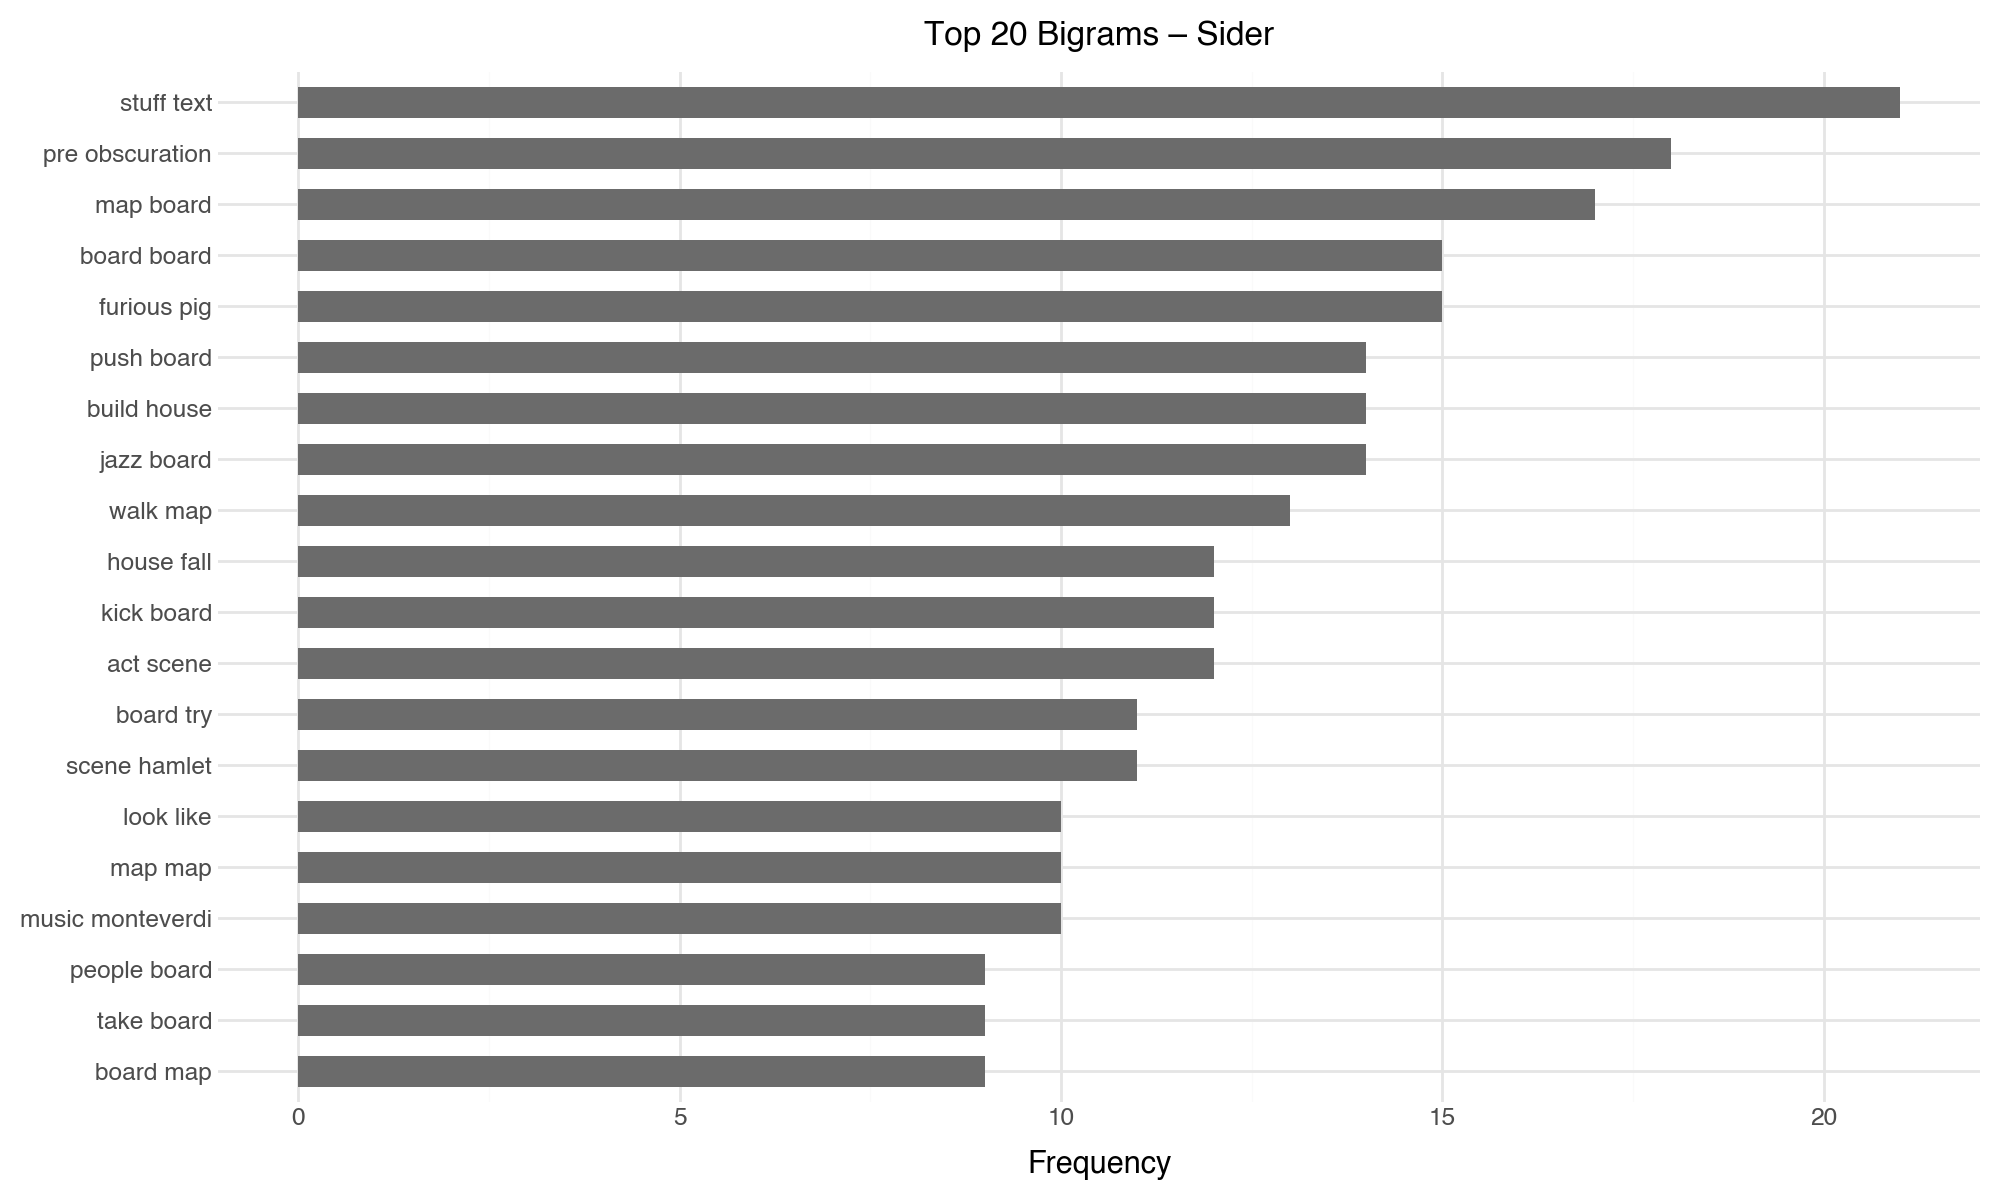

In [16]:
bigrams_df = pd.DataFrame(top_bigrams, columns=['bigram', 'count'])
bigrams_df['bigram'] = pd.Categorical(bigrams_df['bigram'], categories=bigrams_df['bigram'][::-1], ordered=True)

(ggplot(bigrams_df, aes(x='bigram', y='count'))
 + geom_col(fill=BAR_GREY, width=0.6)
 + coord_flip()
 + labs(title=L('Häufigste Bigramme – Sider', 'Top 20 Bigrams – Sider'),
        x='', y=L('Häufigkeit', 'Frequency'))
 + theme(figure_size=(10, 6))
)

## Selected terms over time

Daily counts for a few terms that are central to this production, plotted on a calendar axis. Which terms to track is a manual choice based on knowing the piece.


In [17]:
track_terms = ['board', 'map', 'hamlet', 'ear']
term_colors = dict(zip(track_terms, PASTEL_CYCLE))
print(f"Tracking terms: {track_terms}")

word_counts_by_day = []
for date, group in text_df.groupby("date_only"):
    vectorizer_day = CountVectorizer(stop_words=custom_stopwords, vocabulary=track_terms)
    X_day = vectorizer_day.fit_transform(group["lem_text"])
    counts = X_day.sum(axis=0).A1
    for i, term in enumerate(track_terms):
        word_counts_by_day.append({
            'date': date,
            'word': term,
            'count': counts[i]
        })

word_day_df = pd.DataFrame(word_counts_by_day)
word_day_df['date'] = pd.to_datetime(word_day_df['date'])
word_day_df['word'] = pd.Categorical(word_day_df['word'], categories=track_terms, ordered=True)

Tracking terms: ['board', 'map', 'hamlet', 'ear']


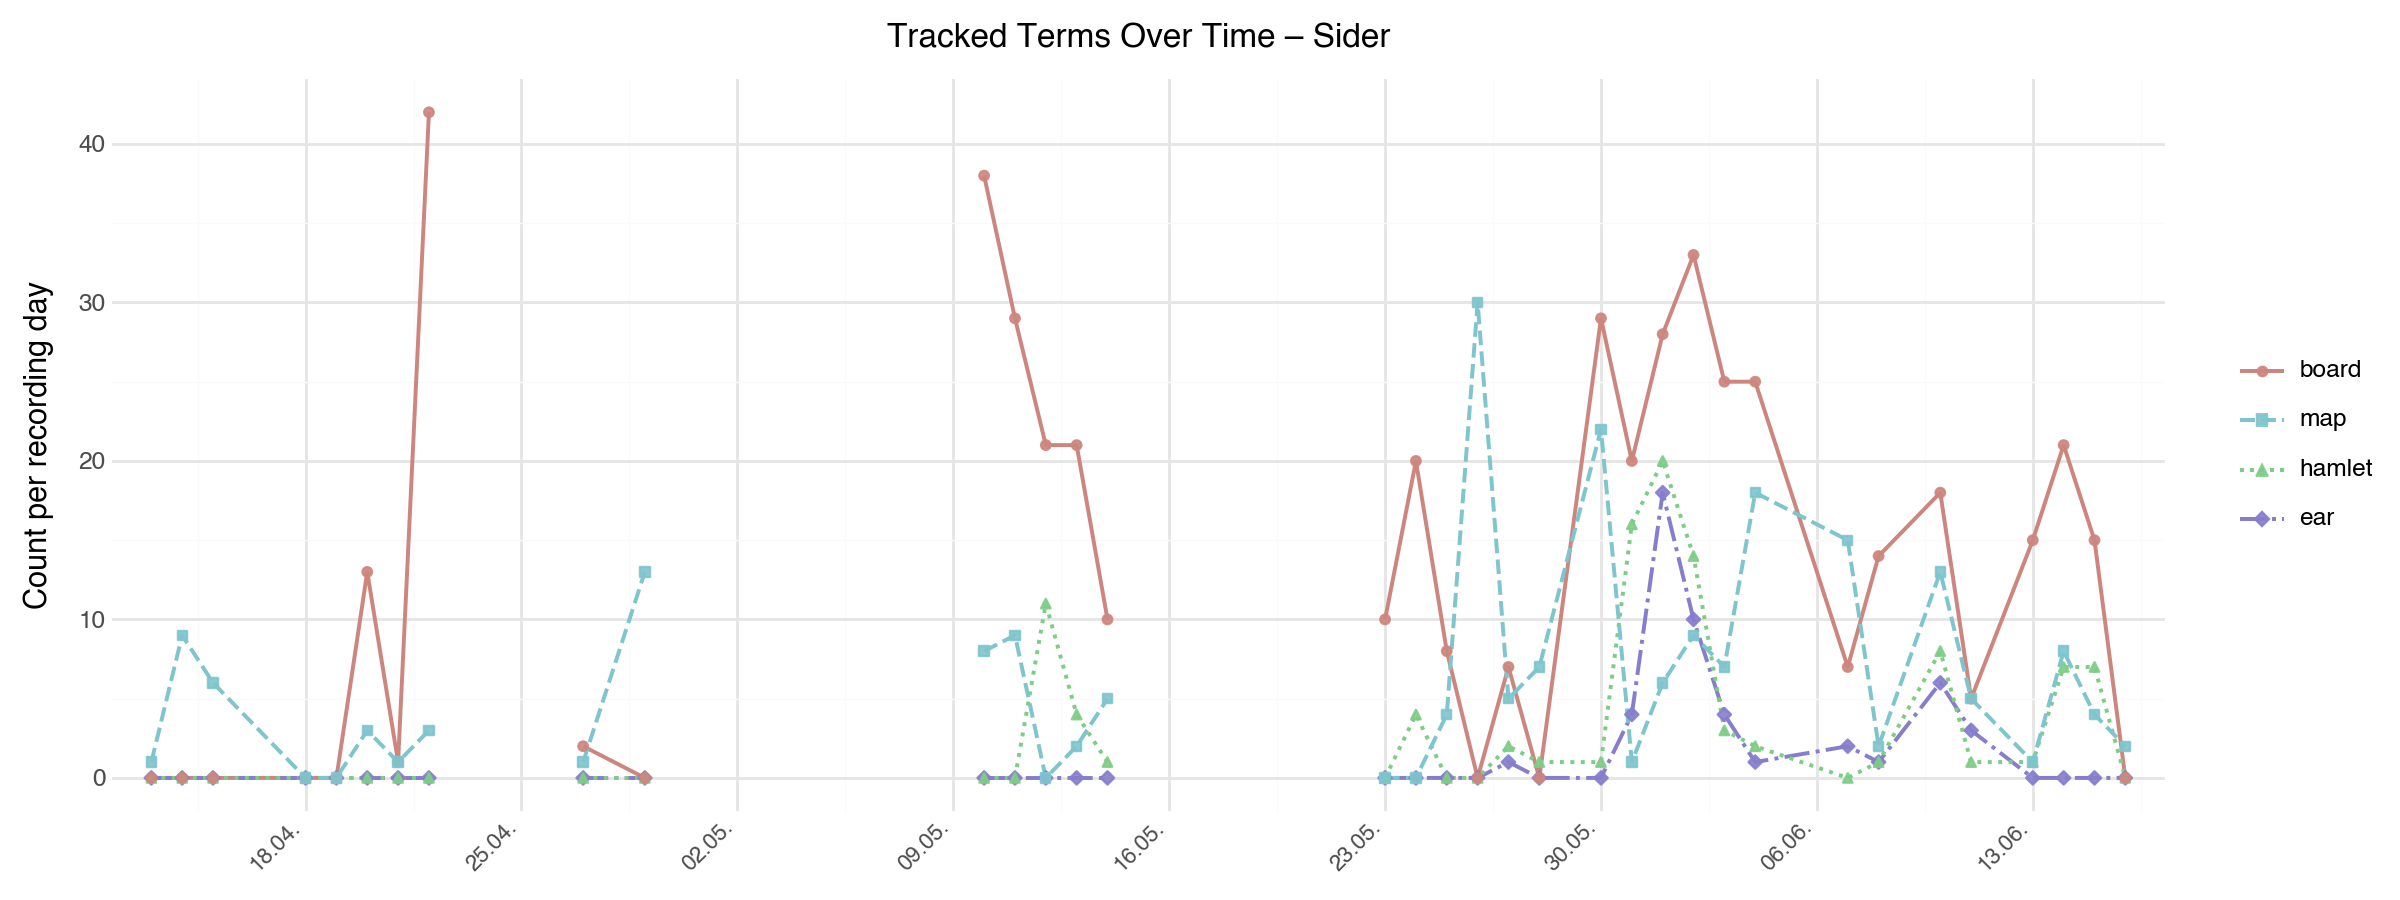

In [18]:
# lines break at gaps of more than GAP_DAYS days without recordings
GAP_DAYS = 3
word_day_df = word_day_df.sort_values(['word', 'date'])
gap = word_day_df.groupby('word', observed=True)['date'].diff().dt.days > GAP_DAYS
word_day_df['segment'] = gap.groupby(word_day_df['word'], observed=True).cumsum()
word_day_df['line_group'] = word_day_df['word'].astype(str) + '_' + word_day_df['segment'].astype(str)

def make_track_plot(lang=None):
    return (ggplot(word_day_df, aes(x='date', y='count', color='word', linetype='word', shape='word'))
     + geom_line(aes(group='line_group'), size=0.8)
     + geom_point(size=1.4, alpha=0.9)
     + scale_color_manual(values=term_colors, name='')
     + scale_linetype_manual(values=dict(zip(track_terms, LINETYPES)), name='')
     + scale_shape_manual(values=dict(zip(track_terms, SHAPES)), name='')
     + scale_x_datetime(date_breaks='1 week', date_labels='%d.%m.', expand=(0.02, 0))
     + labs(title=L('Worthäufigkeit über Zeit – Sider', 'Tracked Terms Over Time – Sider', lang),
            x='', y=L('Häufigkeit pro Aufzeichnungstag', 'Count per recording day', lang))
     + theme(figure_size=(12, 4.5),
             axis_text_x=element_text(rotation=45, hjust=1, size=8),
             legend_position='right'))

p_track = make_track_plot()
p_track

## Correlation over time

Which of the frequent words rise and fall together over the rehearsal days? Spearman rank correlation of the daily counts: on most days a word does not occur at all, and Pearson would be dominated by a few days with a lot of writing. I picked the pairs after looking at the matrix, so the p-values are only descriptive. To check that a correlation is not just the amount of writing per day, the same on relative frequencies (count per lemma token of the day).

In [19]:
cluster_terms = ['hamlet', 'ophelia', 'rhythm', 'ear']
top_words_corr = [t[0] for t in top_words_clean]
vocab = list(dict.fromkeys(top_words_corr + cluster_terms))  # top 20 + cluster terms

word_counts_by_day_corr = []
for date, group in text_df.groupby("date_only"):
    vectorizer_corr = CountVectorizer(stop_words=custom_stopwords, vocabulary=vocab)
    X_corr = vectorizer_corr.fit_transform(group["lem_text"])
    counts = X_corr.sum(axis=0).A1
    row_data = {'date': date}
    for i, word in enumerate(vocab):
        row_data[word] = counts[i]
    word_counts_by_day_corr.append(row_data)

result = pd.DataFrame(word_counts_by_day_corr).sort_values('date')
daily = result.drop(columns=['date'])

print(f"Days: {len(result)}")
print("\nSpearman rank correlation (cluster terms):")
print(daily[cluster_terms].corr(method='spearman').round(3))
print("\nFor comparison, Pearson (sensitive to outlier days, do not cite):")
print(daily[cluster_terms].corr(method='pearson').round(3))

# relative frequencies: count per lemma token of the day
day_tokens = (text_df.groupby('date_only')['lem_text']
              .apply(lambda s: sum(len(t.split()) for t in s))
              .reindex(result['date']).to_numpy())
rel_daily = daily[cluster_terms].div(day_tokens, axis=0)
corr_report = []
for t in cluster_terms[1:]:
    r_abs, p_abs = spearmanr(daily[cluster_terms[0]], daily[t])
    r_rel, p_rel = spearmanr(rel_daily[cluster_terms[0]], rel_daily[t])
    corr_report.append({'pair': f'{cluster_terms[0]}-{t}', 'days': len(result),
                        'rho_abs': round(r_abs, 3), 'p_abs': p_abs,
                        'rho_rel': round(r_rel, 3), 'p_rel': p_rel})
corr_report = pd.DataFrame(corr_report)
print("\nSpearman with p, absolute and relative daily counts:")
print(corr_report.to_string(index=False, formatters={'p_abs': '{:.2g}'.format, 'p_rel': '{:.2g}'.format}))

Days: 35

Spearman rank correlation (cluster terms):
         hamlet  ophelia  rhythm    ear
hamlet    1.000    0.808   0.578  0.565
ophelia   0.808    1.000   0.355  0.509
rhythm    0.578    0.355   1.000  0.341
ear       0.565    0.509   0.341  1.000

For comparison, Pearson (sensitive to outlier days, do not cite):
         hamlet  ophelia  rhythm    ear
hamlet    1.000    0.597   0.595  0.780
ophelia   0.597    1.000   0.280  0.406
rhythm    0.595    0.280   1.000  0.475
ear       0.780    0.406   0.475  1.000

Spearman with p, absolute and relative daily counts:
          pair  days  rho_abs   p_abs  rho_rel   p_rel
hamlet-ophelia    35    0.808 4.4e-09    0.797 9.8e-09
 hamlet-rhythm    35    0.578 0.00028    0.447   0.007
    hamlet-ear    35    0.565 0.00041    0.537 0.00087


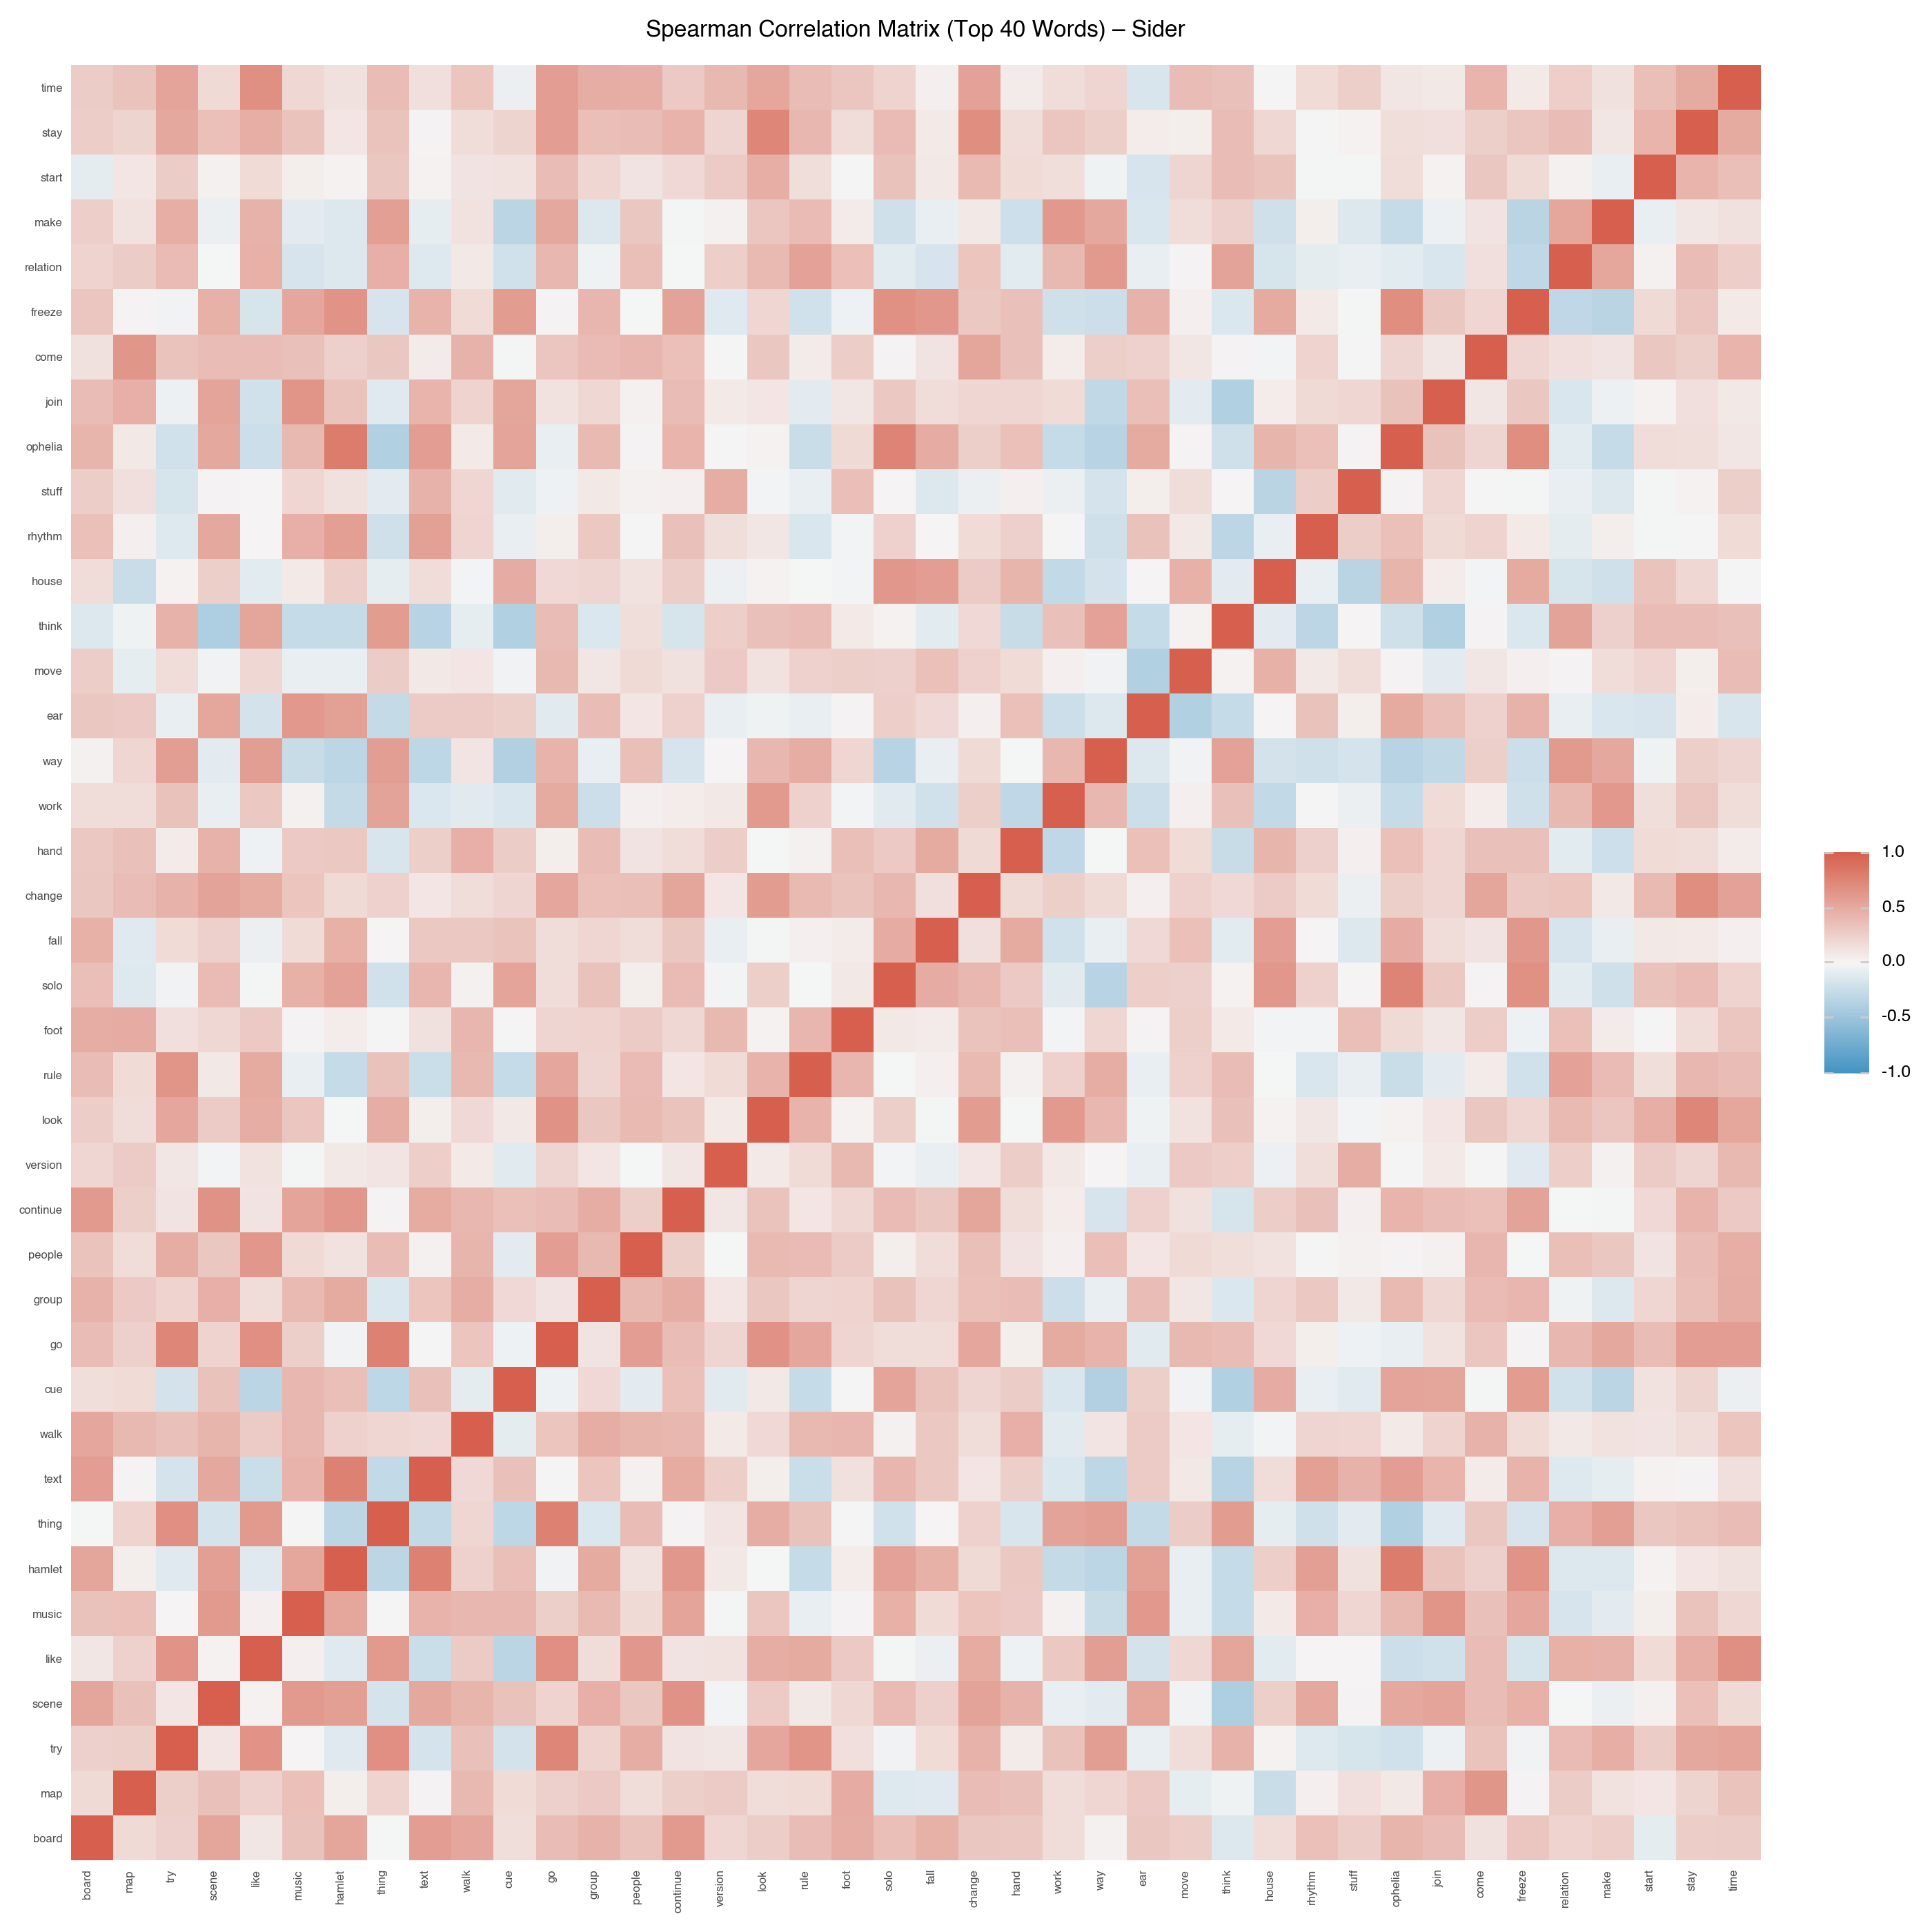

In [20]:
# heatmap of the top 40 words
corr_terms = [w for w, _ in Counter(word_freq).most_common(40)]

corr_counts_by_day = []
for date, group in text_df.groupby("date_only"):
    vectorizer_corr = CountVectorizer(stop_words=custom_stopwords, vocabulary=corr_terms)
    X_corr = vectorizer_corr.fit_transform(group["lem_text"])
    counts = X_corr.sum(axis=0).A1
    corr_counts_by_day.append({"date": date, **dict(zip(corr_terms, counts))})

corr_df = pd.DataFrame(corr_counts_by_day).set_index("date")
corr_matrix = corr_df.corr(method="spearman")

corr_long = (
    corr_matrix
    .reset_index()
    .melt(id_vars="index", var_name="word2", value_name="r")
    .rename(columns={"index": "word1"})
)
corr_long["word1"] = pd.Categorical(corr_long["word1"], categories=corr_terms, ordered=True)
corr_long["word2"] = pd.Categorical(corr_long["word2"], categories=corr_terms, ordered=True)

(ggplot(corr_long, aes(x="word1", y="word2", fill="r"))
 + geom_tile()
 + scale_fill_gradient2(low="#4393c3", mid="#f5f5f5", high="#d6604d", midpoint=0, limits=(-1, 1))
 + labs(title=L(f"Spearman-Korrelationsmatrix (Top {len(corr_terms)} Wörter) – Sider",
                f"Spearman Correlation Matrix (Top {len(corr_terms)} Words) – Sider"),
        x="", y="", fill="ρ")
 + theme(
     axis_text_x=element_text(rotation=90, hjust=1, size=6),
     axis_text_y=element_text(size=6),
     axis_ticks=element_blank(),
     panel_grid=element_blank(),
     figure_size=(14, 14)
 )
)

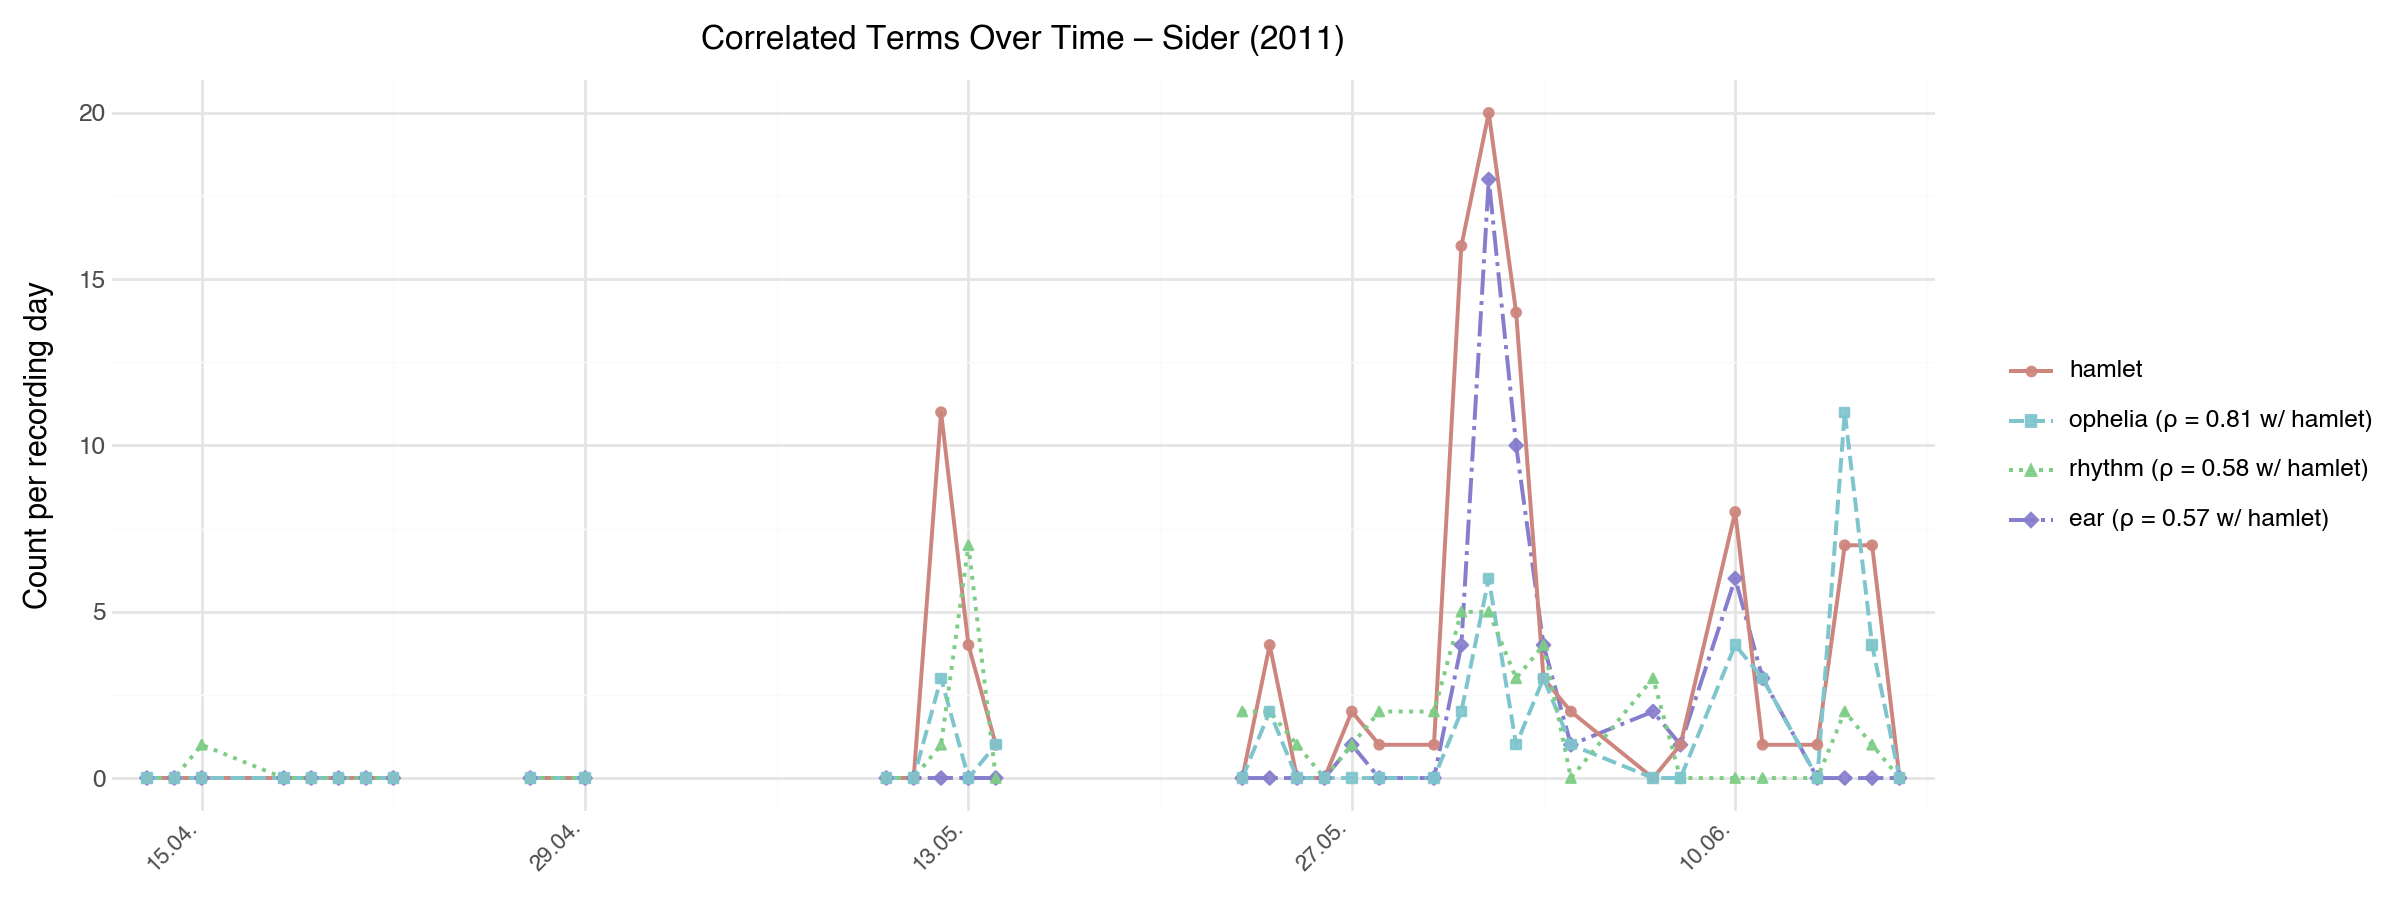

In [21]:
# the correlated terms per recording day (figure in the dissertation)
rho = daily[cluster_terms].corr(method='spearman')[cluster_terms[0]]

def cluster_label(t, lang=None):
    if t == cluster_terms[0]:
        return t
    if (lang or LANG) == 'de':
        return f"{t} (ρ = {de_num(rho[t])} mit {cluster_terms[0]})"
    return f"{t} (ρ = {rho[t]:.2f} w/ {cluster_terms[0]})"

rows_cl = []
for date, group in text_df.groupby('date_only'):
    vec_cl = CountVectorizer(stop_words=custom_stopwords, vocabulary=cluster_terms)
    cnt = vec_cl.fit_transform(group['lem_text']).sum(axis=0).A1
    for i, term in enumerate(cluster_terms):
        rows_cl.append({'date': pd.Timestamp(date), 'word': term, 'count': int(cnt[i])})
cl_df = pd.DataFrame(rows_cl).sort_values(['word', 'date'])
gap_cl = cl_df.groupby('word')['date'].diff().dt.days > GAP_DAYS
cl_df['line_group'] = cl_df['word'] + '_' + gap_cl.groupby(cl_df['word']).cumsum().astype(str)

def make_cluster_plot(lang=None):
    labels = {t: cluster_label(t, lang) for t in cluster_terms}
    order = [labels[t] for t in cluster_terms]
    df = cl_df.copy()
    df['label'] = pd.Categorical(df['word'].map(labels), categories=order, ordered=True)
    return (ggplot(df, aes(x='date', y='count', color='label', linetype='label', shape='label'))
     + geom_line(aes(group='line_group'), size=0.8)
     + geom_point(size=1.4, alpha=0.9)
     + scale_color_manual(values=dict(zip(order, PASTEL_CYCLE)), name='')
     + scale_linetype_manual(values=dict(zip(order, LINETYPES)), name='')
     + scale_shape_manual(values=dict(zip(order, SHAPES)), name='')
     + scale_x_datetime(date_breaks='2 weeks', date_labels='%d.%m.', expand=(0.02, 0))
     + labs(title=L('Korrelierte Terme über Zeit – Sider (2011)', 'Correlated Terms Over Time – Sider (2011)', lang),
            x='', y=L('Häufigkeit pro Aufzeichnungstag', 'Count per recording day', lang))
     + theme(figure_size=(12, 4.5),
             axis_text_x=element_text(rotation=45, hjust=1, size=8),
             legend_position='right'))

p_cluster = make_cluster_plot()
p_cluster

### Word pairs

Which words occur together more often than chance would suggest? Pairs within single annotations (stopwords removed, n ≥ 3), ranked by log-likelihood (G²). Ranked by PMI, the rarest pairs would come first; PMI and NPMI are listed for comparison.

In [22]:
print("\n=== Bigram association ===")

stop_en_pmi = set(stopwords.words("english"))
all_entities = set(confirmed_names)

def pmi_tokens(text):
    tokens = [w.lower() for w in nltk.word_tokenize(text) if w.isalpha()]
    return [w for w in tokens if w not in stop_en_pmi and w not in all_entities]

# one token list per annotation, so pairs don't cross annotations
doc_tokens = [pmi_tokens(t) for t in text_df["lem_text"]]

bigram_measures = BigramAssocMeasures()
finder = BigramCollocationFinder.from_documents(doc_tokens)
finder.apply_freq_filter(3)

N_bigrams = finder.N
pmi_scores = dict(finder.score_ngrams(bigram_measures.pmi))
g2_scores  = dict(finder.score_ngrams(bigram_measures.likelihood_ratio))
assoc = pd.DataFrame([
    {'bigram': f'{a} {b}', 'n': finder.ngram_fd[(a, b)], 'g2': g2_scores[(a, b)],
     'pmi': pmi_scores[(a, b)],
     'npmi': pmi_scores[(a, b)] / -np.log2(finder.ngram_fd[(a, b)] / N_bigrams)}
    for (a, b) in pmi_scores
]).sort_values('g2', ascending=False).reset_index(drop=True)

fmt = {'g2': '{:.1f}'.format, 'pmi': '{:.2f}'.format, 'npmi': '{:.2f}'.format}
print(f"Pairs with n >= 3: {len(assoc)} (bigram tokens: {N_bigrams})")
print("\nTop 20 word pairs by log-likelihood (G²):")
print(assoc.head(20).to_string(formatters=fmt))
print("\nFor comparison, top 20 by PMI:")
print(assoc.sort_values('pmi', ascending=False).head(20).to_string(formatters=fmt))


=== Bigram association ===
Pairs with n >= 3: 269 (bigram tokens: 11137)

Top 20 word pairs by log-likelihood (G²):
              bigram   n    g2   pmi npmi
0        furious pig  15 228.3  9.54 1.00
1    pre obscuration  18 208.9  8.25 0.89
2         stuff text  21 148.1  5.90 0.65
3     racing chasing   9 133.2  9.97 0.97
4       quarter maze   8 131.8 10.44 1.00
5            fry pan   8 121.8 10.12 0.97
6        meta monkey   9 117.5  9.05 0.88
7        build house  14 111.8  6.61 0.69
8      flimsy castle   8  99.7  9.03 0.86
9   music monteverdi  10  85.1  6.42 0.63
10         pig track   7  80.2  8.76 0.82
11       strong fall   9  79.4  7.01 0.68
12           hmm hmm   6  79.4  9.69 0.89
13        house fall  12  74.8  5.57 0.56
14    polonius death   5  74.7 10.27 0.92
15       urban unfit   5  74.7 10.27 0.92
16        jazz board  14  73.0  4.27 0.44
17  mouth morphology   6  72.1  8.90 0.82
18         act scene  11  71.3  5.57 0.56
19       sword fight   5  70.3 10.15 0.91



## Keyness against the Brown corpus

Which words are distinctive compared to general English? G² against the Brown corpus as a filter (p < 0.001), then ranked by Log Ratio, which brings up the rare but exclusive vocabulary. Brown is lemmatised with the same spaCy pipeline (cached in `brown_lemma_freq.csv`). Words missing from Brown get the substitute count 0.5, so their Log Ratio is only an ordering; they are marked in the figure. A bootstrap over the annotations shows how stable the top 30 are.

In [23]:
BROWN_CACHE = 'brown_lemma_freq.csv'

if Path(BROWN_CACHE).exists():
    brown_freq = pd.read_csv(BROWN_CACHE).set_index('lemma')['count'].to_dict()
    print(f'Loaded lemmatised Brown frequencies from cache ({len(brown_freq)} lemma types)')
else:
    print('Building lemmatised Brown frequency cache (one-off, ~2 min)...')
    _nlp_fast = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
    _freq = Counter()
    _sents = [' '.join(s) for s in brown.sents()]
    for _doc in _nlp_fast.pipe(_sents, batch_size=200):
        _freq.update(
            tok.lemma_.lower() for tok in _doc
            if tok.is_alpha and not tok.is_stop and len(tok.lemma_) >= 2
        )
    pd.DataFrame(sorted(_freq.items()), columns=['lemma', 'count']).to_csv(BROWN_CACHE, index=False)
    brown_freq = dict(_freq)
    print(f'Saved {BROWN_CACHE} ({len(brown_freq)} lemma types)')

N_your = int(sum(word_freq.values()))
N_ref  = int(sum(brown_freq.values()))
print(f'Target corpus tokens: {N_your}')
print(f'Reference corpus tokens (Brown, lemmatised): {N_ref}')

Loaded lemmatised Brown frequencies from cache (32531 lemma types)
Target corpus tokens: 11137
Reference corpus tokens (Brown, lemmatised): 469996


In [24]:
MIN_FREQ = 5        # minimum frequency in the target corpus
G2_CRIT  = 10.83    # p < 0.001

def compute_g2(O1, O2, N1, N2):
    """Dunning's G² (signed: positive = overrepresented in the target corpus)."""
    def safe_log(x):
        return np.log(x) if x > 0 else 0.0
    N = N1 + N2
    p  = (O1 + O2) / N if N > 0 else 0.0
    p1 = O1 / N1 if N1 > 0 else 0.0
    p2 = O2 / N2 if N2 > 0 else 0.0
    L_null = (O1 * safe_log(p)  + (N1 - O1) * safe_log(1 - p) +
              O2 * safe_log(p)  + (N2 - O2) * safe_log(1 - p))
    L_alt  = (O1 * safe_log(p1) + (N1 - O1) * safe_log(1 - p1) +
              O2 * safe_log(p2) + (N2 - O2) * safe_log(1 - p2))
    g2 = 2 * (L_alt - L_null)
    return g2 if p1 >= p2 else -g2

def log_ratio(O1, O2, N1, N2):
    """Hardie's Log Ratio; zero counts are replaced by 0.5."""
    return float(np.log2(((O1 if O1 > 0 else 0.5) / N1) /
                         ((O2 if O2 > 0 else 0.5) / N2)))

rows = []
for word, O1 in word_freq.items():
    if O1 < MIN_FREQ:
        continue
    O2 = brown_freq.get(word, 0)
    rows.append({
        'word': word, 'your_count': int(O1), 'ref_count': int(O2),
        'g2': compute_g2(O1, O2, N_your, N_ref),
        'log_ratio': log_ratio(O1, O2, N_your, N_ref),
    })
keyness_ref = pd.DataFrame(rows)

keyness_sig = (
    keyness_ref[keyness_ref['g2'] >= G2_CRIT]
    .sort_values('log_ratio', ascending=False)
    .reset_index(drop=True)
)
print(f'Words with frequency >= {MIN_FREQ}: {len(keyness_ref)}')
print(f'Significant at p < 0.001 (G² >= {G2_CRIT}): {len(keyness_sig)}')
print('\nTop 30 by Log Ratio:')
print(keyness_sig.head(30).to_string(index=False,
      formatters={'g2': '{:.1f}'.format, 'log_ratio': '{:+.2f}'.format}))

B_BOOT = 200
rng = np.random.default_rng(42)
doc_vectorizer = CountVectorizer(stop_words=custom_stopwords)
X_docs = doc_vectorizer.fit_transform(text_df['lem_text'])
boot_vocab = doc_vectorizer.get_feature_names_out()
ref_counts = np.array([brown_freq.get(w, 0) for w in boot_vocab])
top30 = keyness_sig.head(30)['word'].tolist()
in_top30 = Counter()
for _ in range(B_BOOT):
    rows_b = rng.integers(0, X_docs.shape[0], X_docs.shape[0])
    counts_b = np.asarray(X_docs[rows_b].sum(axis=0)).ravel()
    N_b = counts_b.sum()
    cand = [(w, log_ratio(o1, o2, N_b, N_ref)) for w, o1, o2 in zip(boot_vocab, counts_b, ref_counts)
            if o1 >= MIN_FREQ and compute_g2(o1, o2, N_b, N_ref) >= G2_CRIT]
    ranked = {w for w, _ in sorted(cand, key=lambda r: -r[1])[:30]}
    in_top30.update(w for w in top30 if w in ranked)
keyness_sig['top30_share'] = keyness_sig['word'].map(lambda w: in_top30[w] / B_BOOT if w in top30 else np.nan)
keyness_sig['absent_in_ref'] = keyness_sig['ref_count'] == 0
print(f'\nBootstrap ({B_BOOT} resamples): share in which a word is in the top 30 again')
print(keyness_sig.head(30)[['word', 'your_count', 'ref_count', 'log_ratio', 'top30_share']].to_string(index=False,
      formatters={'log_ratio': '{:+.2f}'.format, 'top30_share': '{:.2f}'.format}))
print(f"Median stability of the top 30: {keyness_sig.head(30)['top30_share'].median():.2f}")

Words with frequency >= 5: 476
Significant at p < 0.001 (G² >= 10.83): 255

Top 30 by Log Ratio:
       word  your_count  ref_count     g2 log_ratio
    ophelia          41          0  308.9    +11.76
obscuration          33          0  248.6    +11.44
      dopey          23          0  173.3    +10.92
  soliloquy          23          0  173.3    +10.92
     improv          15          0  113.0    +10.31
       saka          13          0   97.9    +10.10
        cue          82          4  586.0     +9.76
        duo           9          0   67.8     +9.57
       meta           9          0   67.8     +9.57
   polonius           9          0   67.8     +9.57
     hamlet         104          7  732.3     +9.29
 imprinting           6          0   45.2     +8.98
    upstage           6          0   45.2     +8.98
   claudius           6          0   45.2     +8.98
       duet          24          2  166.8     +8.98
      video          23          2  159.4     +8.92
gravedigger        


Bootstrap (200 resamples): share in which a word is in the top 30 again
       word  your_count  ref_count log_ratio top30_share
    ophelia          41          0    +11.76        1.00
obscuration          33          0    +11.44        1.00
      dopey          23          0    +10.92        1.00
  soliloquy          23          0    +10.92        1.00
     improv          15          0    +10.31        0.89
       saka          13          0    +10.10        0.97
        cue          82          4     +9.76        1.00
        duo           9          0     +9.57        0.90
       meta           9          0     +9.57        0.96
   polonius           9          0     +9.57        0.92
     hamlet         104          7     +9.29        1.00
 imprinting           6          0     +8.98        0.64
    upstage           6          0     +8.98        0.62
   claudius           6          0     +8.98        0.62
       duet          24          2     +8.98        0.79
      video    

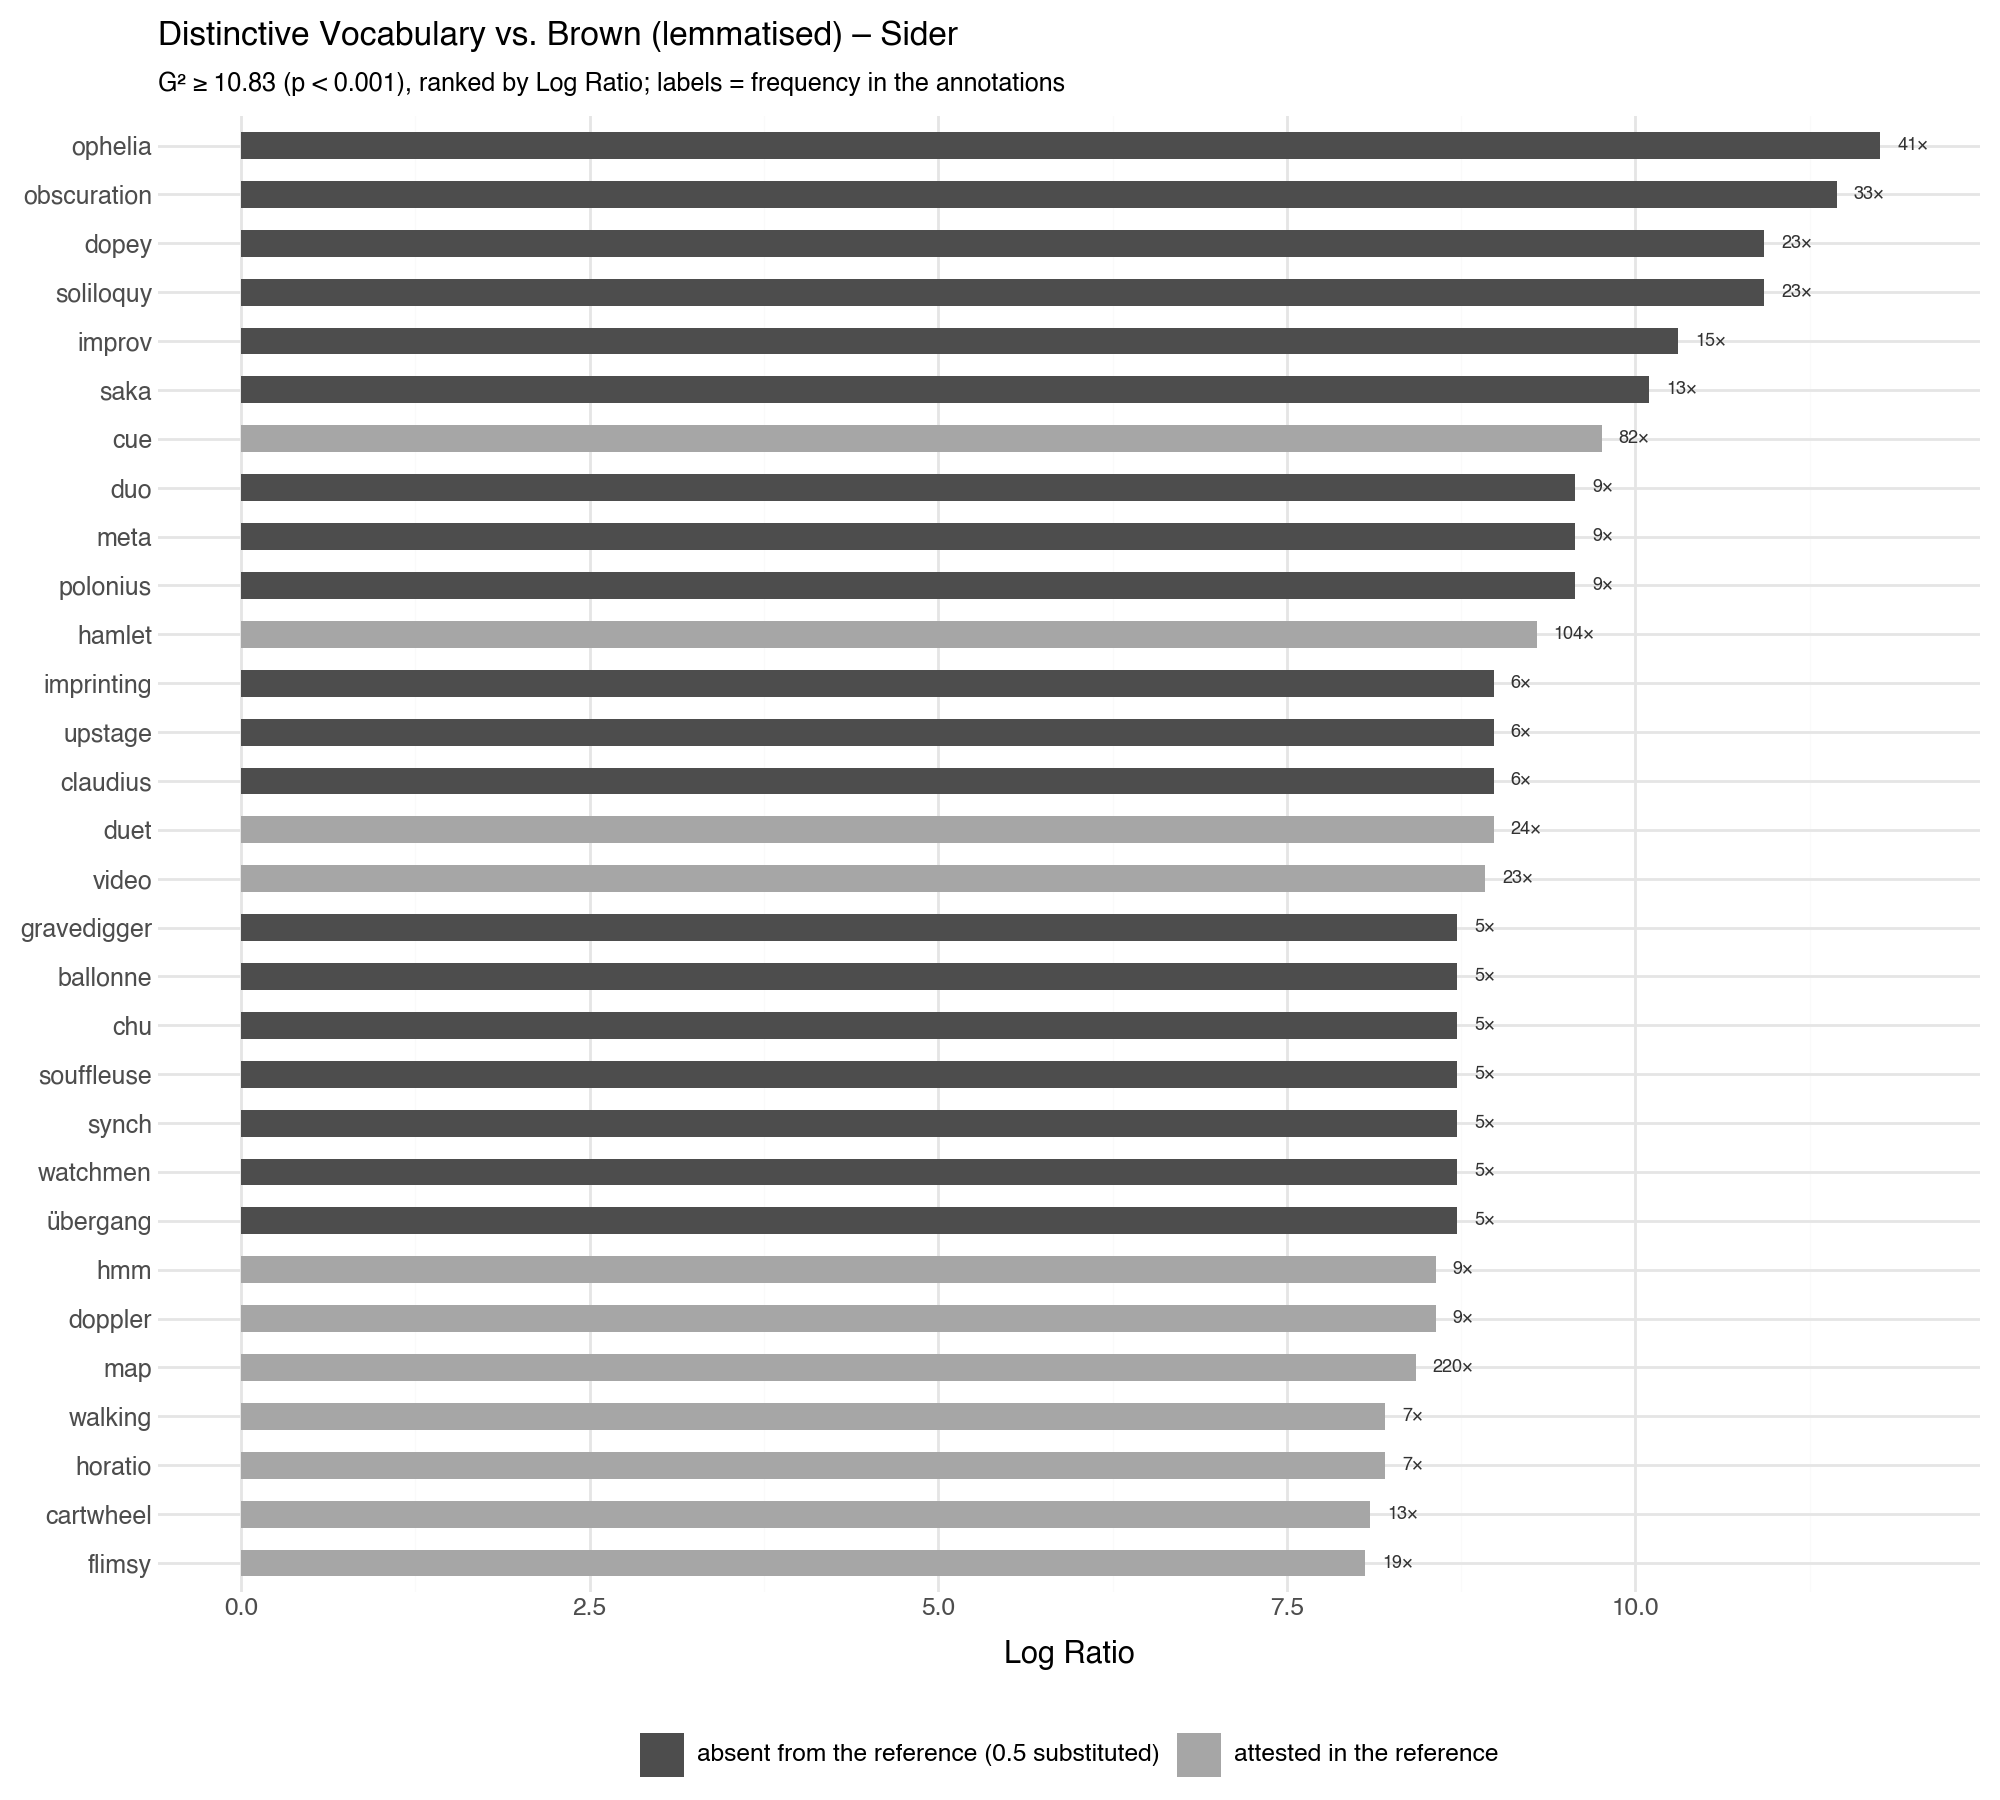

In [25]:
def make_keyness_plot(lang=None, top=30):
    df = keyness_sig.head(top).copy()
    df['label'] = df['your_count'].astype(str) + '×'
    absent  = L('im Referenzkorpus nicht belegt (Ersatzwert 0,5)', 'absent from the reference (0.5 substituted)', lang)
    present = L('im Referenzkorpus belegt', 'attested in the reference', lang)
    df['ref'] = np.where(df['ref_count'] == 0, absent, present)
    df['word'] = pd.Categorical(df['word'], categories=df['word'][::-1], ordered=True)
    crit = de_num(G2_CRIT) if (lang or LANG) == 'de' else f'{G2_CRIT}'
    return (ggplot(df, aes(x='word', y='log_ratio', fill='ref'))
     + geom_col(width=0.55)
     + geom_text(aes(label='label'), ha='left', nudge_y=0.12, size=6.5, color='#333333')
     + scale_fill_manual(values={absent: '#4d4d4d', present: '#a6a6a6'}, name='')
     + coord_flip()
     + labs(title=L(f'Distinktives Vokabular ggü. Referenzkorpus (Brown, lemmatisiert) – {PIECE_TITLE}',
                    f'Distinctive Vocabulary vs. Brown (lemmatised) – {PIECE_TITLE}', lang),
            subtitle=L(f'G² ≥ {crit} (p < 0,001), sortiert nach Log Ratio; Zahl = Häufigkeit in den Annotationen',
                       f'G² ≥ {crit} (p < 0.001), ranked by Log Ratio; labels = frequency in the annotations', lang),
            x='', y='Log Ratio')
     + theme(figure_size=(10, 9),
             axis_text_y=element_text(size=9),
             legend_position='bottom'))

p_key = make_keyness_plot()
p_key

## Topic modelling

BERTopic clusters sentence embeddings instead of counting words, which suits the short, telegraphic annotations better than classic bag-of-words topic models (LDA gave heavily overlapping topics on this material).


### BERTopic

Sentences from the cleaned annotations, embedded with `all-MiniLM-L6-v2`, reduced with UMAP (fixed seed) and clustered with HDBSCAN (BERTopic default, `min_cluster_size=10`). A space is inserted after punctuation directly followed by a letter, otherwise BERTopic merges words separated only by a period or slash into one keyword. The performer names stay in the sentences for the embeddings but are excluded from the topic keywords. To see whether the maps topic depends on the seed, the clustering is repeated with ten other seeds.

In [26]:
from sentence_transformers import SentenceTransformer
from umap import UMAP

print("\n=== BERTopic Analysis (seeded) ===")
BERTOPIC_SEED = 42

sentences = []
timestamps = []
def space_after_punct(text):
    return re.sub(r"([.,;:!?/])(?=[A-Za-z])", r"\1 ", text)

for _, row in text_df.iterrows():
    for sentence in sent_tokenize(space_after_punct(row["clean_text"])):
        sentence_clean = sentence.strip()
        if sentence_clean:
            sentences.append(sentence_clean)
            timestamps.append(row["date"])
print(f"Total sentences: {len(sentences)}")

# the model is downloaded automatically on the first run
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = embedding_model.encode(sentences, show_progress_bar=True)

umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                  metric='cosine', random_state=BERTOPIC_SEED)
# names stay in the sentences, not in the keywords
name_stop = [n for n in confirmed_names if n.isalpha()]
vectorizer_model = CountVectorizer(stop_words=list(stop_en.union(name_stop)))
topic_model = BERTopic(umap_model=umap_model, vectorizer_model=vectorizer_model)
topics, probs = topic_model.fit_transform(sentences, embeddings)

print(f"Number of topics found: {len(set(topics)) - 1}")
print(f"Outlier sentences (topic -1): {sum(1 for t in topics if t == -1)}")


=== BERTopic Analysis (seeded) ===
Total sentences: 2401


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/76 [00:00<?, ?it/s]

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


Number of topics found: 59
Outlier sentences (topic -1): 547


In [27]:
topic_model.get_topic_info()[['Topic', 'Count', 'Name']].head(20)

,Topic,Count,Name
0,-1,547,-1_cue_map_audience_something
1,0,119,0_hamlet_queen_ghost_scene
2,1,97,1_davids_observer_board_kicking
3,2,86,2_force_failure_atmo_relation
4,3,81,3_leans_behind_tries_feet
5,4,80,4_boards_board_people_free
6,5,76,5_adagio_structure_urban_morphology
7,6,68,6_map_mapping_maps_walking
8,7,67,7_music_monteverdi_bubble_whistle
9,8,64,8_solo_snaps_saka_car


In [28]:
# Inspect a specific topic by ID
topic_model.get_topic(0)

[('hamlet', 0.0997250680679265),
 ('queen', 0.04112868602792679),
 ('ghost', 0.0360205965090853),
 ('scene', 0.03419287683322436),
 ('hamlets', 0.03150527274954123),
 ('polonius', 0.03015608011181116),
 ('soliloquy', 0.029217944783373462),
 ('king', 0.02560652006478942),
 ('ear', 0.023263931600171456),
 ('act', 0.022761351168701704)]

In [29]:
# the maps topic
def topic_words(tid):
    return [w for w, _ in topic_model.get_topic(tid)]

candidates = []
for tid in topic_model.get_topic_info()['Topic']:
    if tid == -1:
        continue
    score = sum(w in ('map', 'maps', 'mapping') for w in topic_words(tid)[:10])
    if score >= 1:
        candidates.append((score, -tid, tid))
candidates.sort(reverse=True)
assert candidates, 'No maps topic found, inspect get_topic_info() manually.'
TARGET_TID = candidates[0][2]
target_label = '_'.join([str(TARGET_TID)] + topic_words(TARGET_TID)[:4])
print(f'Selected topic: {TARGET_TID}  ->  {target_label}')

Selected topic: 6  ->  6_map_mapping_maps_walking


In [30]:
# Top-10 keywords + c-TF-IDF scores of the target topic
kw = pd.DataFrame(topic_model.get_topic(TARGET_TID)[:10], columns=['word', 'score'])
kw

,word,score
0,map,0.070397
1,mapping,0.033455
2,maps,0.032921
3,walking,0.030799
4,yesterday,0.026929
5,space,0.022727
6,leading,0.022304
7,place,0.021889
8,slice,0.021550
9,way,0.020556


In [31]:
# same embeddings, UMAP seeds 0-9: Jaccard overlap of the target topic's sentences with the best match
target_idx = {i for i, t in enumerate(topics) if t == TARGET_TID}
stab_rows = []
for seed in range(10):
    tm_s = BERTopic(umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                                    metric='cosine', random_state=seed),
                    vectorizer_model=vectorizer_model)
    topics_s, _ = tm_s.fit_transform(sentences, embeddings)
    members = {}
    for i, t in enumerate(topics_s):
        if t != -1:
            members.setdefault(t, set()).add(i)
    best_tid, best_j = None, 0.0
    for t, idx in members.items():
        j = len(target_idx & idx) / len(target_idx | idx)
        if j > best_j:
            best_tid, best_j = t, j
    words_s = [w for w, _ in tm_s.get_topic(best_tid)][:4] if best_tid is not None else []
    stab_rows.append({'seed': seed, 'topics': len(members),
                      'best_match': '_'.join([str(best_tid)] + words_s), 'jaccard': round(best_j, 2)})
stability = pd.DataFrame(stab_rows)
print(stability.to_string(index=False))
print(f"Median Jaccard overlap with the target topic of the seed-{BERTOPIC_SEED} run: {stability['jaccard'].median():.2f}")

 seed  topics                 best_match  jaccard
    0      60 4_map_maps_mapping_walking     0.87
    1      61   4_map_maps_space_mapping     0.85
    2      56 8_map_mapping_maps_walking     0.88
    3      54   4_map_maps_space_mapping     0.87
    4      61   3_map_maps_space_mapping     0.86
    5      57 6_map_maps_mapping_walking     0.94
    6      59 5_map_mapping_maps_walking     0.87
    7      59 5_map_mapping_maps_walking     0.91
    8      55 7_map_mapping_maps_walking     0.89
    9      62 3_map_maps_mapping_walking     0.80
Median Jaccard overlap with the target topic of the seed-42 run: 0.87


In [32]:
# topic per recording day, zero on days without it
day_stamps = [pd.Timestamp(t).normalize() for t in timestamps]
topics_over_time = topic_model.topics_over_time(docs=sentences, topics=topics, timestamps=day_stamps)
single_topic = topics_over_time[topics_over_time['Topic'] == TARGET_TID].copy().sort_values('Timestamp')

recording_days = pd.DatetimeIndex(sorted(set(day_stamps)), name='date')
per_day = (single_topic.set_index('Timestamp')[['Frequency', 'Words']]
           .reindex(recording_days).reset_index())
per_day['Frequency'] = per_day['Frequency'].fillna(0).astype(int)

per_day[per_day['Frequency'] > 0].assign(date=lambda d: d['date'].dt.date).reset_index(drop=True)

,date,Frequency,Words
0,2011-04-14,9,"slice, map, world, life, place"
1,2011-04-15,4,"mapping, arrows, gave, circles, akirasada"
2,2011-04-18,2,"globe, upstairs, doodle, simply, device"
3,2011-04-20,1,"launches, accumulating, launch, become, falls"
4,2011-04-21,1,"performativity, cracks, private, heterotopia, ..."
5,2011-04-22,2,"mapping, referring, basically, kinds, thinking"
6,2011-04-27,2,"material, ea, scales, recover, quantative"
7,2011-04-29,1,"mapping, inferential, dimensional, inference, ..."
8,2011-05-10,1,"many, places, put, idea, different"
9,2011-05-11,2,"flandona, accumulate, kept, necessary, letting"


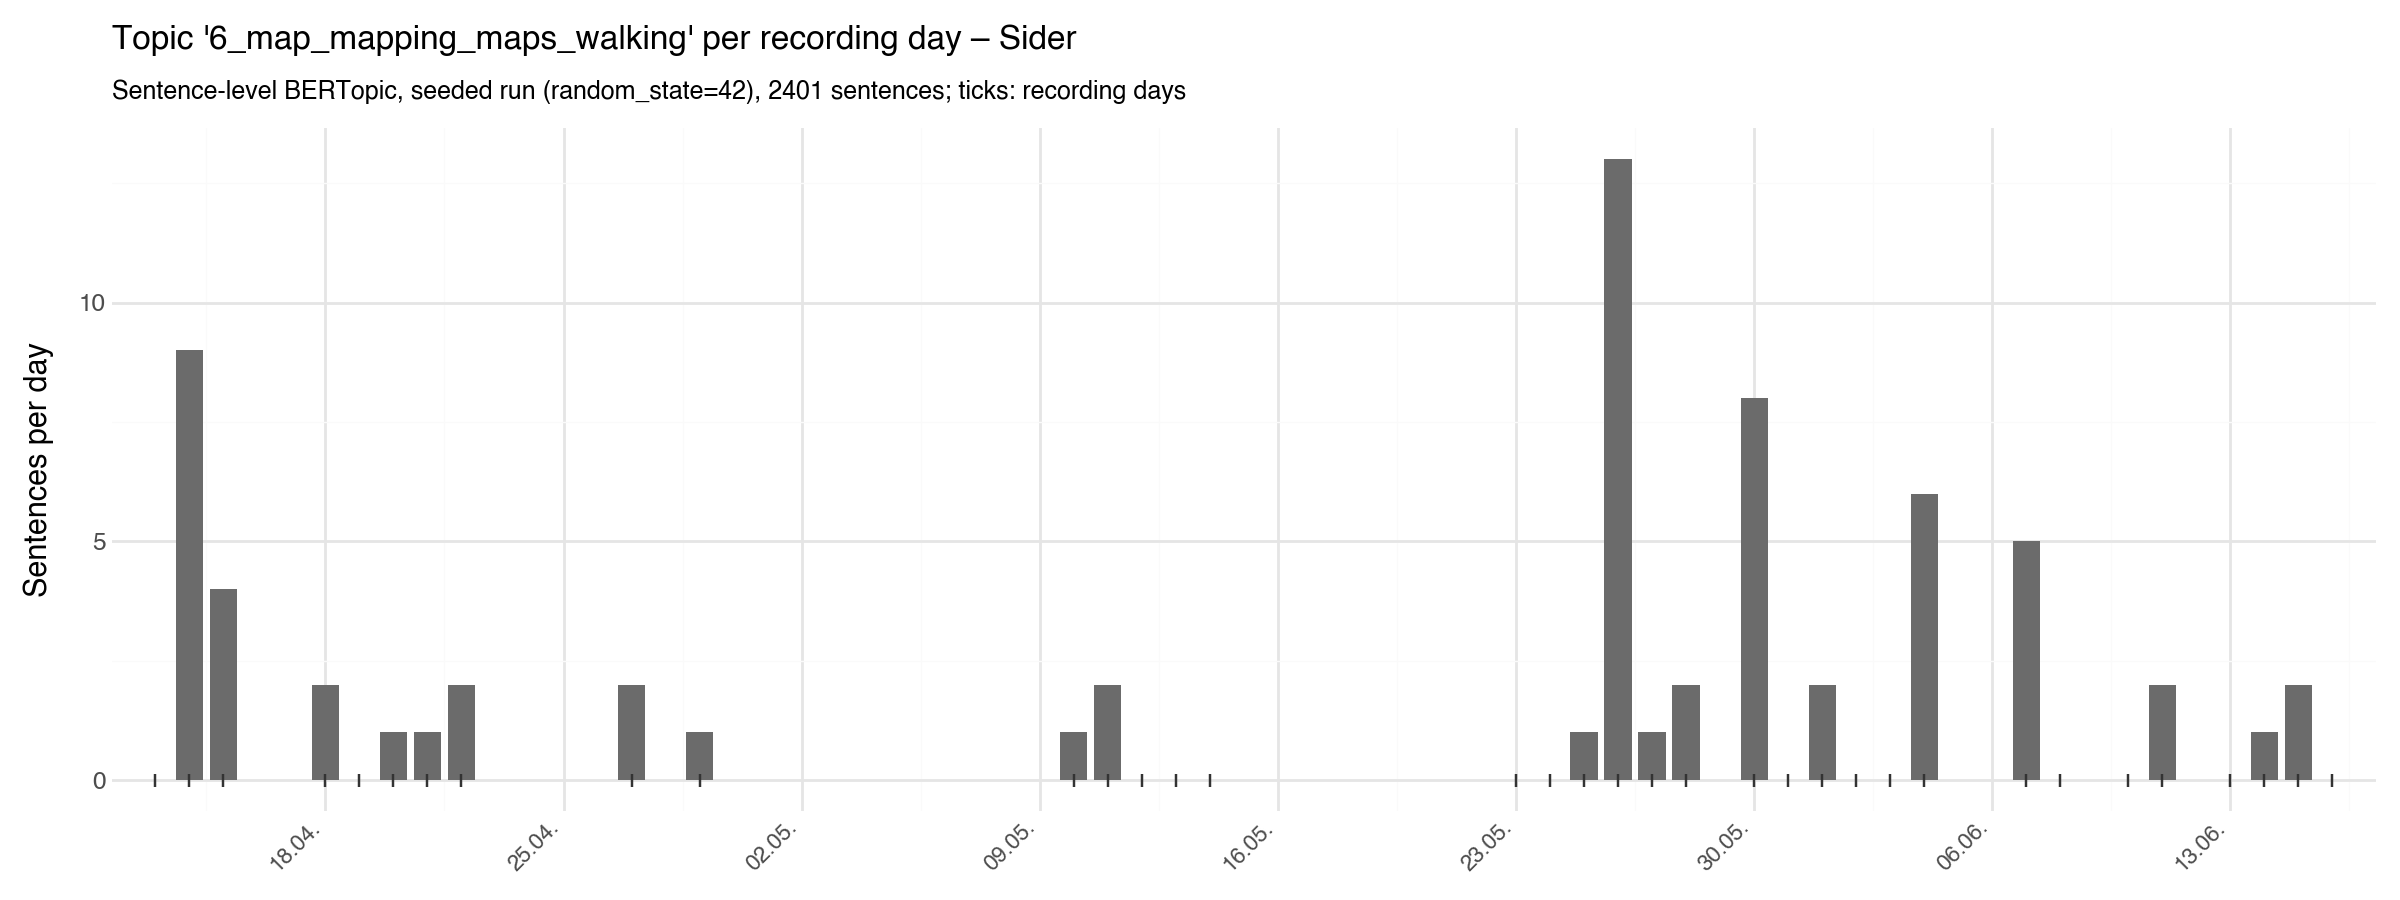

In [33]:
def make_topic_time_plot(lang=None):
    present = per_day[per_day['Frequency'] > 0]
    return (
        ggplot(per_day, aes(x='date', y='Frequency'))
        + geom_col(data=present, fill=BAR_GREY, width=0.8)
        + geom_point(aes(y=0), shape='|', size=2.2, color='#333333')
        + scale_x_datetime(date_breaks='1 week', date_labels='%d.%m.', expand=(0.02, 0))
        + labs(title=L(f"Topic '{target_label}' je Aufzeichnungstag – {PIECE_TITLE}",
                       f"Topic '{target_label}' per recording day – {PIECE_TITLE}", lang),
               subtitle=L(f'Satzweises BERTopic, Seed-Lauf (random_state={BERTOPIC_SEED}), {len(sentences)} Sätze; '
                          'Striche: Aufzeichnungstage',
                          f'Sentence-level BERTopic, seeded run (random_state={BERTOPIC_SEED}), {len(sentences)} sentences; '
                          'ticks: recording days', lang),
               x='', y=L('Sätze pro Tag', 'Sentences per day', lang))
        + theme(figure_size=(12, 4.5),
                axis_text_x=element_text(rotation=45, hjust=1, size=8))
    )

p_topic = make_topic_time_plot()
p_topic

Highlighted topics: {6: '6_map_mapping_maps_walking', 4: '4_boards_board_people_free', 12: '12_text_rhythm_loop_stuff'}


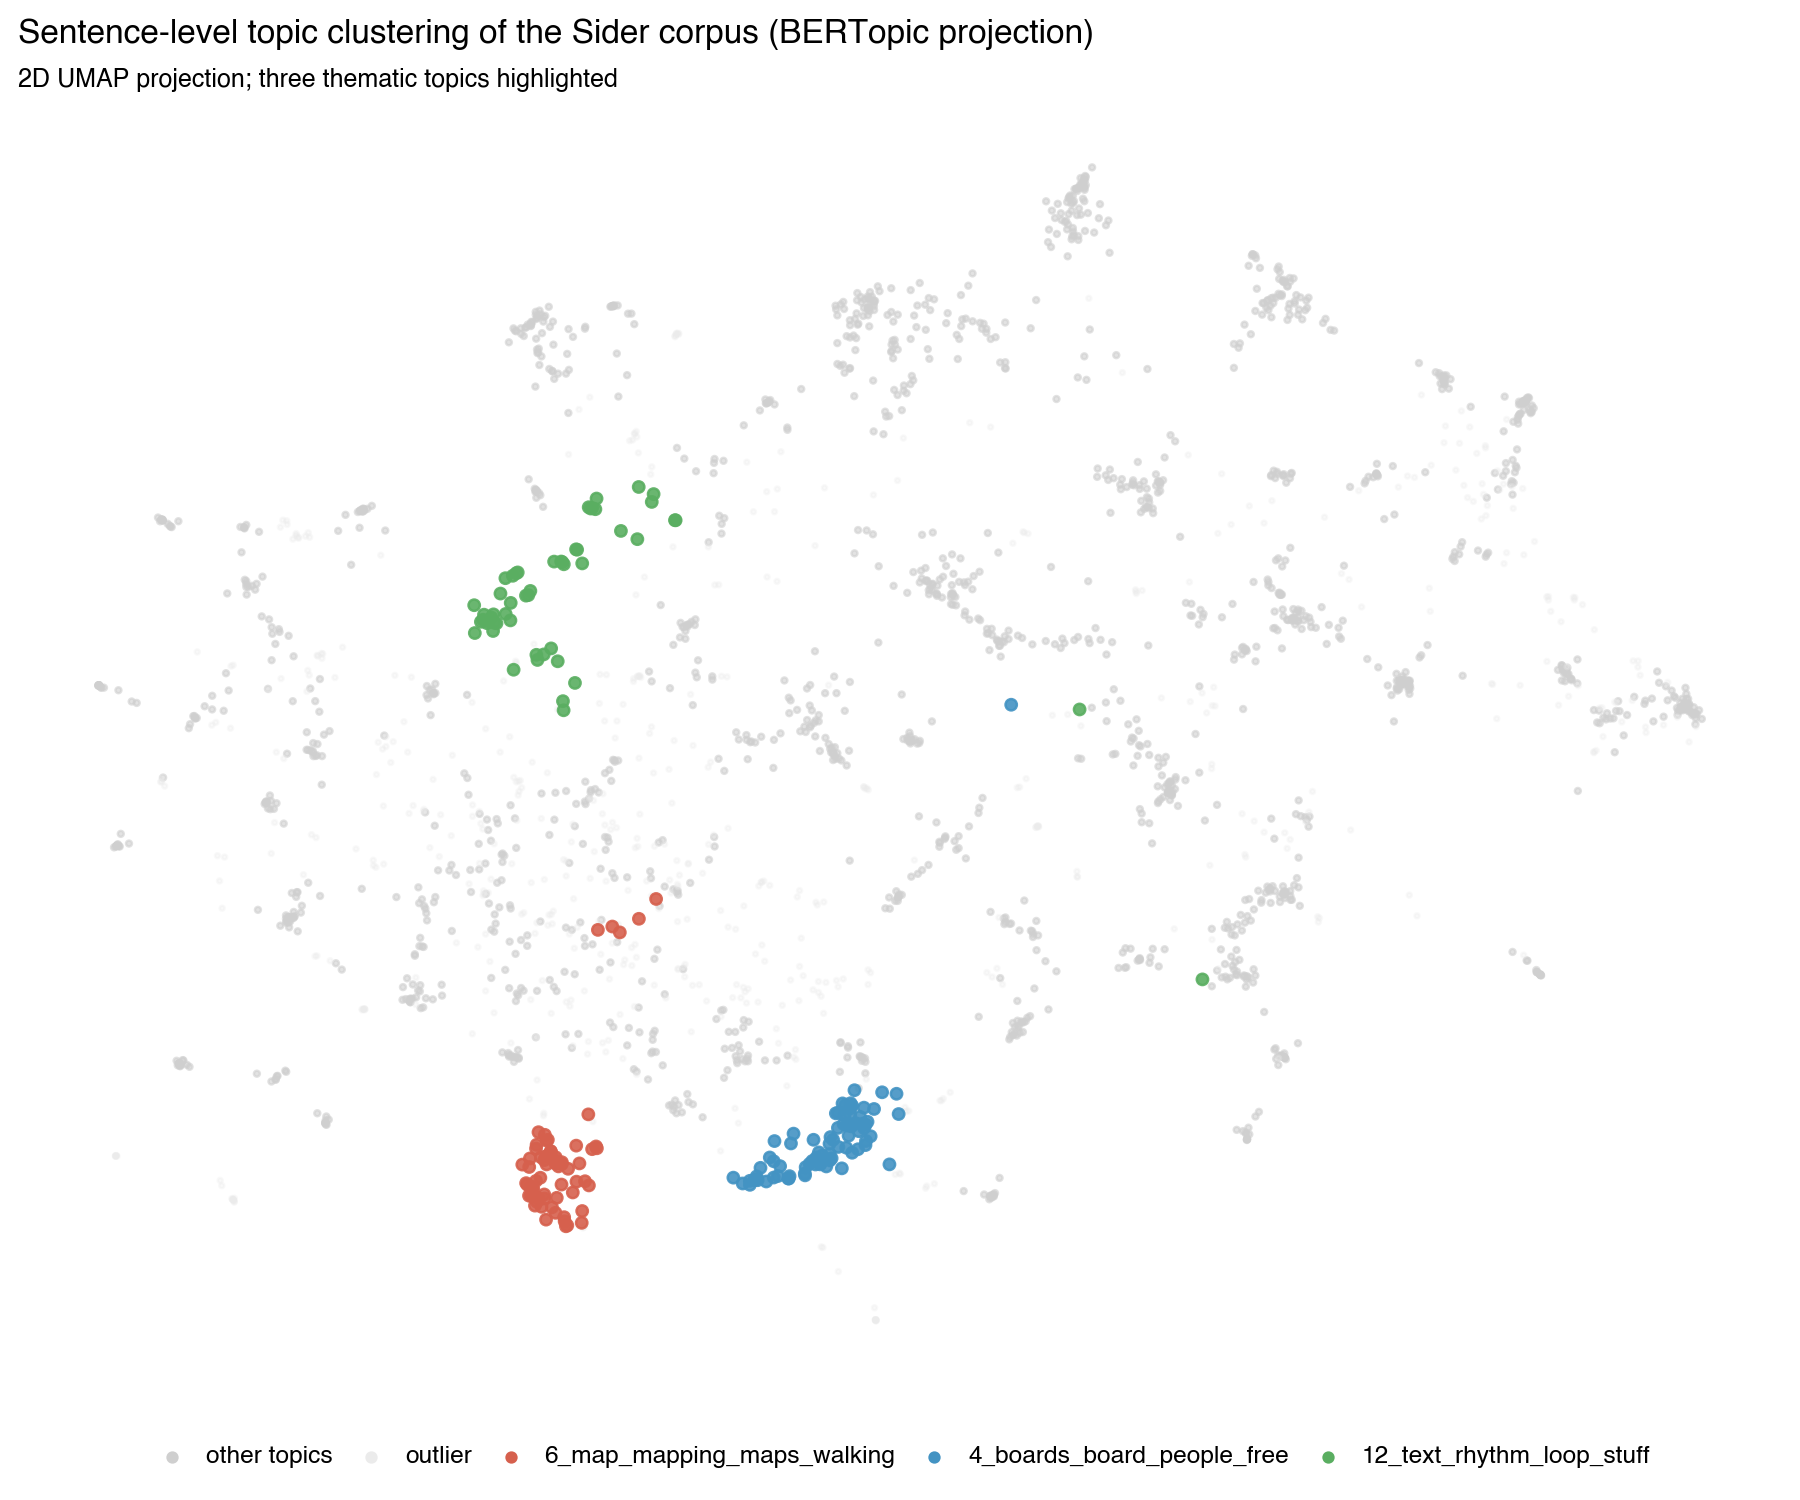

In [34]:
# separate 2D UMAP of the same embeddings; maps, boards and text/rhythm highlighted
HIGHLIGHT_SPECS = [
    ('maps',        ('map', 'maps', 'mapping')),
    ('boards',      ('board', 'boards')),
    ('text/rhythm', ('text', 'rhythm', 'speakers')),
]
highlight = {}
topic_ids = [t for t in topic_model.get_topic_info()['Topic'] if t != -1]
for spec_name, spec_words in HIGHLIGHT_SPECS:
    ranked = sorted(((sum(w in spec_words for w in topic_words(t)[:10]), -t, t) for t in topic_ids),
                     reverse=True)
    assert ranked[0][0] >= 1, f'No topic found for {spec_name}, inspect get_topic_info().'
    tid = ranked[0][2]
    if tid not in highlight:
        highlight[tid] = '_'.join([str(tid)] + topic_words(tid)[:4])
print('Highlighted topics:', highlight)

emb2d = UMAP(n_neighbors=15, n_components=2, min_dist=0.0,
             metric='cosine', random_state=BERTOPIC_SEED).fit_transform(embeddings)
proj = pd.DataFrame({'x': emb2d[:, 0], 'y': emb2d[:, 1], 'topic': topics})
lab_outlier = L('Ausreißer', 'outlier')
lab_other   = L('andere Topics', 'other topics')
proj['group'] = proj['topic'].map(highlight)
proj.loc[proj['group'].isna() & (proj['topic'] == -1), 'group'] = lab_outlier
proj['group'] = proj['group'].fillna(lab_other)
group_order = [lab_other, lab_outlier] + list(highlight.values())
proj['group'] = pd.Categorical(proj['group'], categories=group_order, ordered=True)
proj = proj.sort_values('group')  # draw highlighted topics last (on top)

HL_COLORS = ['#d6604d', '#4393c3', '#5aae61']
group_colors = {lab_other: '#cfcfcf', lab_outlier: '#ebebeb',
           **dict(zip(highlight.values(), HL_COLORS))}
group_sizes  = {lab_other: 0.7, lab_outlier: 0.5, **{v: 1.8 for v in highlight.values()}}
group_alphas = {lab_other: 0.6, lab_outlier: 0.3, **{v: 0.9 for v in highlight.values()}}

p_clust = (
    ggplot(proj, aes(x='x', y='y', color='group', size='group', alpha='group'))
    + geom_point()
    + scale_color_manual(values=group_colors, name='')
    + scale_size_manual(values=group_sizes, guide=None)
    + scale_alpha_manual(values=group_alphas, guide=None)
    + labs(title=L('Satzweise Topic-Cluster des Sider-Korpus (BERTopic-Projektion)',
                   'Sentence-level topic clustering of the Sider corpus (BERTopic projection)'),
           subtitle=L('2D-UMAP-Projektion; drei thematische Topics hervorgehoben',
                      '2D UMAP projection; three thematic topics highlighted'),
           x='', y='')
    + theme(figure_size=(9, 7.5),
            axis_text=element_blank(), axis_ticks=element_blank(),
            panel_grid=element_blank(),
            legend_position='bottom')
)
p_clust

## Figures for the dissertation

German labels, print size, written to `figures/`.

In [35]:
FIG_DIR.mkdir(exist_ok=True)

def save_print(p, name, size=PRINT_SIZE, extra=None):
    p = p + PRINT_THEME + theme(figure_size=size)
    if extra is not None:
        p = p + extra
    p.save(FIG_DIR / name, dpi=300, verbose=False)
    print('saved', FIG_DIR / name)

save_print(make_cluster_plot('de') + theme(legend_position='bottom'),
           'sider_correlated_terms_per_day_de.png', size=(5.8, 3.3))            # Abb. 4.8
assoc.head(20).to_csv(FIG_DIR / 'sider_bigrams_g2_top20.csv', index=False)      # Tab. 4.4
corr_report.to_csv(FIG_DIR / 'sider_correlation_report.csv', index=False)
keyness_sig.head(30).to_csv(FIG_DIR / 'sider_keyness_brown_top30.csv', index=False)
stability.to_csv(FIG_DIR / 'sider_topic_seed_stability.csv', index=False)

saved figures/sider_correlated_terms_per_day_de.png
